# Sell the Fed-hike tail: short SR3 puts, Fed-decision contracts as the hedge

## S0 · Summary

| question | answer |
|---|---|
| Does a short out-of-the-money SR3 put, sold every quarter, earn a volatility premium over the bill once the direction is taken out; and does the owner's trade as sent hold on today's Polymarket prices? | rendered below from the run |

Two parts share this notebook. The history (S2 to S4, S6) tests the systematic rule from 1990 on the Treasury par curve; it is
pinned and its scalars are the ones registered for research-001. The trade as sent (S1.3, S5.2, S6) is read live from
Polymarket when the notebook runs and moves every run; the 2026-09-27 read sits beside the new one in S5.2. The block below
is filled by the manifest cell of S7.

In [1]:
from IPython.display import HTML, Markdown, display
S0_HANDLE = display(Markdown("_S0 is rendered by the manifest cell of S7 when the run finishes._"), display_id=True)

**Sell the Fed-hike tail: short SR3 puts** · **NO SIZE**

**Research question** Does a short SR3 put, sold every quarter, earn a volatility premium over the bill once the direction is out, and does the owner's trade hold today?

NO SIZE. The volatility term is +0.15% a year (95% -0.01 to +0.35); the +0.69% directional term rode a forward bias that reads -1.6 bp since 2016.

**Implementation**

| | |
|:--|:--|
| Trade | Short SR3 put, z 1 SD above the forward, every quarter |
| Hold | To expiry; exercised futures closed at once |
| Venue | CME SR3 options (modelled); Polymarket Fed contracts hedge |
| Capital | USD 1.0M cash earning the 3M bill; 40 lots |
| Costs | USD 0.89 option, 1.25 futures [U]; 0.25 bp slippage [U] |
| Window | 1990-06-15 to 2026-09-11, 145 quarters, 12 regimes |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| 40 lots | Volatility term, ann. | +0.15% | 95% -0.01 to +0.35 | FAIL |
| 40 lots | Directional term, ann. | +0.69% |  | INFO |
| 2008 on | Break-even vol, implied over realized | 0.93x | market 1.24 to 1.45x | PASS |
| 40 lots | Maximum drawdown | -2.47% | limit 15% | PASS |

**Return, 40 lots, a year**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Volatility term (the craft) | +0.15% | above 0 | FAIL |
| Directional term (the lottery) | +0.69% |  |  |
| Premium collected | 1.01% |  |  |
| Excess over the T-bill | +0.84% | T-bill 2.70% |  |
| Return with the T-bill | 3.55% |  |  |
| Net P&L over the bill, USD | +306,221 |  |  |

**Risk, 40 lots**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Volatility, ann. | 1.09% |  |  |
| Sharpe ratio | 0.78 |  |  |
| Sortino ratio | 0.98 |  |  |
| Maximum drawdown | -2.47% | limit 15% | PASS |
| Drawdown duration, longest | 455 days |  |  |
| Worst quarter | -0.61% |  |  |
| Expired worthless | 97.1% |  |  |
| Worst stress-grid loss | -13.61% | limit 25% | PASS |

**Is it luck**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Volatility term, 95% interval | -0.01% to +0.35% | above 0 | FAIL |
| p-value, term above zero | 0.052 |  | INFO |
| Deflated Sharpe | 0.23 | 9 choices tried | INFO |
| Probabilistic Sharpe | 0.87 |  | INFO |
| Quarters sold | 137 | of 145 | INFO |

**Robustness**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Volatility term since 2008 | +0.14% | above 0 | PASS |
| Worst cost cell, volatility term | -0.13% | above 0 | FAIL |
| Volatility term, MOVE-priced vol | +0.30% | above 0 | PASS |
| Break-even vol, total, strike moving | 0.48x |  | INFO |
| Rule or hedge adopted | none |  | INFO |

**The trade as sent, live read**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Premium after fee and one tick, USD | 2,714 | quote 3,000 | INFO |
| YES cost at live asks, USD | 824 | quote 660 | INFO |
| December YES average price | 3.2c | assumed 1.5c | FLAG |
| January YES filled | 56% | needs 100% | FLAG |
| Worst of the 27 rows, USD | -11,507 |  | INFO |
| A 2022-style run, USD | -61,507 |  | INFO |

**Size, information only**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Lots the limits allow | 73 lots |  | INFO |
| Return, ann. at 73 lots | +1.54% |  |  |
| Maximum drawdown at 73 lots | -3.89% | limit 15% | PASS |
| Limit that binds | stress |  | INFO |

**Size**

| Lots per USD 1M | Return, ann. | Maximum drawdown | Worst stress loss | Verdict |
|:--|--:|--:|--:|:--|
| 40 lots | +0.84% | -2.47% | -13.61% | PASS |
| **73 lots** | **+1.54%** | **-3.89%** | **-24.85%** | **PASS** |
| 146 lots | +3.08% | -7.26% | -49.69% | FAIL |

Next bet: SR3 futures and options history (B-0212 archive) in place of the bill carrier and the modelled premium.  
Not shown: SR3 option prices (the premium is a model [U]) or a forward bias on SR3 itself · study checks 44/44 ALL PASS · one window of 12 regimes.


## S1 · Setup

| question | gate |
|---|---|
| What exactly was run, on what, with which assumptions? | every venue number is a fact card read in this run; the stated numbers equal the code (PROSE) |

### S1.1 · Parameters

Every knob that is OURS (owner-set or `[U]`) lives in the one cell below; the venue's numbers are S1.2.

In [2]:
# ---- parameters: owner-set, study-set or [U]; never a venue number (those are S1.2, read from the cards) ----
STUDY_ID = "2026-09-27-xasset-sofr-hike-tail-put-bill"
RUN_ID = "research-001"                  # pre-registered in lab/research/results-log.md on 2026-09-27
KIND, DESK = "strategy", "lab/research"
TITLE = "Sell the Fed-hike tail: short SR3 puts"
QUESTION = ("Does a short out-of-the-money SR3 put, sold every quarter, earn a volatility premium over the bill once the "
            "direction is taken out, and does the owner's trade as sent hold on today's Polymarket prices?")
EQUITY = 1_000_000.0     # owner 2026-09-27: cash collateral earning the 3M bill; every P&L below is EXCESS over it
LOTS = 40                # owner's trade: 40 lots = USD 1,000 per bp beyond the strike. S6 sweeps it
Z = 1.0                  # strike distance in implied standard deviations above the forward [U, rule parameter]
KAPPA = 1.0              # implied / trailing realized normal vol. 1.0 = the model charges realized vol [U]
SLIP_BP = 0.25           # [U] slippage per option fill (one tick of the four nearest quarterlies)
SLIP_FUT_BP = 0.25       # [U] slippage closing the futures an exercised option delivers
MIN_PREM_BP = 0.5        # [U] do not sell an option worth less than this (two ticks)
DD_LIMIT_PCT = 15.0      # [U] desk drawdown limit, % of equity, fixed before S6 ran
STRESS_GRID = (10, 25, 40, 60, 100, 150)   # [U] moves of the forward against the book on entry day, bp, with vol x 1.5
STRESS_LIMIT_PCT = 25.0  # [U] the worst of them is the margin proxy, capped at this % of equity
FWD_TOL_BP = 5.0         # [U] tolerance on today's Polymarket-built forward when solving the quote's implied vol
WALK_CAP = 0.20          # [U] the highest Polymarket ask a hedge walk will pay
SPLIT, RECENT = "2008-01-01", "2016-01-01"
NBOOT, BLOCK_Q, NW_LAGS, SEED = 2000, 12, 8, 7
CURVE_FROM, MOVE_FROM = "1990-01-01", "2002-11-13"
# the owner's trade as sent, 2026-09-27: 40 puts at 95.4375 for USD 3,000, 22,013 Oct and 22,013 Dec "Fed hikes 50bp" YES for USD 660
OWN_LOTS, OWN_K_PX, OWN_PREM_USD, OWN_YES, OWN_YES_PX, OWN_HEDGE_USD = 40, 95.4375, 3000.0, 22013, 0.015, 660.0

### S1.2 · Assumptions

| item | statement |
|---|---|
| the trade | every quarter, sell the next quarterly SR3 put one implied standard deviation above the forward rate; hold to expiry |
| what should pay | implied vol above what the rate then does: the volatility premium, the craft term |
| what is risked | a hike path faster than the curve priced; the loss grows linearly with the rate, USD 1,000 per bp at 40 lots |
| the control | the book split into its directional term (a long futures position of the option's delta: the lottery) and its volatility term (the rest: the craft). The gates read the volatility term |
| the order of proof | data, the unlevered base, out of sample and luck, rules and hedges, then sizing |
| the refusal | no size is chosen unless gates 1 and 2 pass |
| the carrier | the Treasury par curve, 1M to 1Y: the forward at entry; the same forward at expiry is the futures' price. Before 2018 the traded contract was Eurodollar (LIBOR); bills carry flight-to-quality and supply effects SOFR does not. The forward bias is NOT shown to transfer to SR3 |
| the premium | Bachelier on the forward; implied normal vol = `KAPPA` x trailing 63-day realized vol of the 3x6 forward; no skew. MODEL [U]: the fund holds no SR3 option history |
| today's implied vol | solved from the owner's quote on a forward built from Polymarket's decision markets: one quote [U] |
| Polymarket fees and decision dates | each market's own `fee_rate` / `fee_exponent` through `match.pm_taker_fee`; a meeting's date is its event's end date in New York [API] |

The contract terms and the CME fees are the fact cards (`platform/venues/cme/facts/`), read in the next cell with their tags and read
dates. The math (the forward, Bachelier, the SR3 calendar, the quarterly engine) is `fundplat.quant.tradfi.rates_options` with its own
`verify`; the statistics over a result stay in this notebook.

In [3]:
import datetime as dt, json, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from fundplat.data.tradfi import rates as RATES, eodhd as EOD, refrates as REFR, fedpolicy as FP
from fundplat.data.predmkts import polymarket as PM
from fundplat.quant.predmkts import match as MATCH
from fundplat.quant.core import stats as ST, report as REPORT, figstyle, summary_card
from venues import facts as FACTS               # the cards: pure JSON, the tag travels with the value

warnings.filterwarnings("ignore", category=DeprecationWarning)
NOW = dt.datetime.now(dt.timezone.utc)
RUN_AT = NOW.strftime("%Y-%m-%dT%H:%MZ")
TODAY = pd.Timestamp(NOW.date())
RNG = np.random.default_rng(SEED)

CARD_IDS = {"USD per bp per contract": ("cme", "contract.multiplier_and_inverse"), "CME fee per option": ("cme", "fee.option.taker"),
            "CME fee per futures": ("cme", "fee.taker.base"), "SR3 option strikes": ("cme", "option.strike.intervals"),
            "SR3 calendar": ("cme", "expiry.times"), "SR3 option history": ("cme", "history.options")}
FCARDS = {k: FACTS.tagged(*v) for k, v in CARD_IDS.items()}
CTAG = {k: v["tag"] for k, v in FCARDS.items()}
USD_PER_BP = float(FCARDS["USD per bp per contract"]["value"])
FEE_OPT, FEE_FUT = float(FCARDS["CME fee per option"]["value"]), float(FCARDS["CME fee per futures"]["value"])
STRIKE_STEP_BP = 6.25    # the number in CME's strike rule; held to the card text on the next line
assert "6.25 basis point" in str(FCARDS["SR3 option strikes"]["value"]), FCARDS["SR3 option strikes"]["value"]

INK, INK2, MUTED, GRID, AXIS = (figstyle.NEUTRAL[k] for k in ("ink", "ink2", "muted", "grid", "axis"))
C_BOOK, C_HEDGE = figstyle.IDENTITY["SKHY"], figstyle.IDENTITY["SKHX"]       # the short put is blue, a hedge is amber, in every figure
C_DIR, C_VOL, C_COST = figstyle.QUANTITY["basis"], figstyle.QUANTITY["funding"], figstyle.QUANTITY["fees"]   # the directional term, the volatility term, costs
C_GOOD, C_LOSS, GOLD = figstyle.VERDICT["good"], figstyle.VERDICT["bad"], figstyle.TABLE["gold"]
plt.rcParams.update({"figure.dpi": 96, "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
LEG = dict(frameon=False)
KFMT = FuncFormatter(lambda v, _: f"{v:,.0f}")
FIGURES = []
WIN_STAMP = r"\d{4}-\d\d-\d\d \d\d:\d\dZ"      # a live read's window is its read stamp


def ask(ax, q, sub):
    ax.set_title(q, loc="left", fontsize=11, fontweight="bold", color=INK, pad=18)
    ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8, color=MUTED, va="bottom")


def show(f, tag, kind, findings, top=0.80, window_re=None, **kw):
    # findings below the chart, the figure rules checked, the figure listed for the manifest
    w, h = f.get_size_inches()
    f.set_size_inches(w, h + figstyle.nlines(findings) * figstyle.LINE_IN + 0.5)
    figstyle.finish(f, findings, top, **kw)
    figstyle.check(f, tag, **({"window_re": window_re} if window_re else {}))
    FIGURES.append({"id": tag, "section": f"S{tag[5]}", "title": figstyle.title_of(f).strip(), "kind": kind})
    plt.show()


def mdt(df, fmt=None):
    # a DataFrame as a markdown table (no tabulate in the venv)
    fmt = fmt or {}
    cols = [str(c) for c in df.columns]
    out = ["| " + " | ".join([df.index.name or ""] + cols) + " |", "|" + "---|" * (len(cols) + 1)]
    for i, r in df.iterrows():
        cells = [("-" if (isinstance(v, float) and np.isnan(v)) else fmt.get(c, "{}").format(v)) for c, v in zip(df.columns, r)]
        out.append("| " + " | ".join([str(i)] + cells) + " |")
    return "\n".join(out)


usd = lambda v: f"USD {v:,.0f}"
sgn = lambda v, d=2: f"{v:+,.{d}f}"

AS = pd.DataFrame([{"item": k, "value": str(c["value"])[:150] + ("..." if len(str(c["value"])) > 150 else ""),
                    "unit": c.get("unit") or "-", "tag": c["tag"], "read": c["read"]} for k, c in FCARDS.items()]).set_index("item")
AS.index.name = "venue number (card)"
display(Markdown(mdt(AS)))
OURS = pd.DataFrame([("equity", f"{usd(EQUITY)} cash earning the 3M T-bill; all P&L is EXCESS over that bill", "owner 2026-09-27"),
                     ("base book", f"{LOTS} puts per quarter = {usd(LOTS * USD_PER_BP)} per bp beyond the strike (the trade as sent)", "owner's trade"),
                     ("strike rule", f"z {Z:g} implied SD above the entry forward", "[U]"),
                     ("premium", f"Bachelier, kappa {KAPPA:g} x trailing 63-day realized vol", "MODEL [U]"),
                     ("costs", f"{SLIP_BP:g} bp per option fill, {SLIP_FUT_BP:g} bp per futures close; fees from the cards", "[U]"),
                     ("desk limits", f"max drawdown {DD_LIMIT_PCT:g}%, worst stress-grid loss {STRESS_LIMIT_PCT:g}% of equity (the margin proxy)", "[U], fixed before S6"),
                     ("the trade as sent", f"short {OWN_LOTS} puts at {OWN_K_PX} for {usd(OWN_PREM_USD)}; long {OWN_YES:,} Oct and {OWN_YES:,} Dec 'Fed hikes 50bp' YES for {usd(OWN_HEDGE_USD)}", "owner, 2026-09-27")],
                    columns=["item", "value", "source"]).set_index("item")
OURS.index.name = "our choice"
display(Markdown(mdt(OURS)))
PROSE = {"40 lots": (LOTS, 40), "USD 1,000 per bp": (LOTS * USD_PER_BP, 1000.0), "equity 1M": (EQUITY, 1e6),
         "z = 1": (Z, 1.0), "kappa = 1": (KAPPA, 1.0), "drawdown limit 15%": (DD_LIMIT_PCT, 15.0), "stress limit 25%": (STRESS_LIMIT_PCT, 25.0),
         "3.0 bp quote": (OWN_PREM_USD / (OWN_LOTS * USD_PER_BP), 3.0), "strike step 6.25": (STRIKE_STEP_BP, 6.25),
         "YES at 1.5c = USD 660": (round(2 * OWN_YES * OWN_YES_PX), OWN_HEDGE_USD)}
BAD = {k: v for k, v in PROSE.items() if v[0] != v[1]}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"
print(f"run {RUN_AT} · {len(FCARDS)} cards read · {len(PROSE)} stated numbers held to the code")

| venue number (card) | value | unit | tag | read |
|---|---|---|---|---|
| USD per bp per contract | 25.0 | USD per basis point per contract | [U] | 2026-09-27 |
| CME fee per option | 0.89 | USD per contract per side | [U] | 2026-09-27 |
| CME fee per futures | 1.25 | USD per contract per side | [U] | 2026-09-27 |
| SR3 option strikes | Rule 460A01.E.3 as amended effective trade date 2020-10-12 (CME's filing to the CFTC): 6.25 basis point exercise prices, listed daily in a range from ... | - | [1] | 2026-09-27 |
| SR3 calendar | Futures: the Reference Quarter runs from the third Wednesday of the contract month to the third Wednesday three months later (end excluded). Quarterly... | - | [U] | 2026-09-27 |
| SR3 option history | n/a: no free source of SR3 option prices or settlements was found (2026-09-27). CME DataMine is paid; Yahoo carries no option chain history for SR3. A... | - | [U] | 2026-09-27 |

| our choice | value | source |
|---|---|---|
| equity | USD 1,000,000 cash earning the 3M T-bill; all P&L is EXCESS over that bill | owner 2026-09-27 |
| base book | 40 puts per quarter = USD 1,000 per bp beyond the strike (the trade as sent) | owner's trade |
| strike rule | z 1 implied SD above the entry forward | [U] |
| premium | Bachelier, kappa 1 x trailing 63-day realized vol | MODEL [U] |
| costs | 0.25 bp per option fill, 0.25 bp per futures close; fees from the cards | [U] |
| desk limits | max drawdown 15%, worst stress-grid loss 25% of equity (the margin proxy) | [U], fixed before S6 |
| the trade as sent | short 40 puts at 95.4375 for USD 3,000; long 22,013 Oct and 22,013 Dec 'Fed hikes 50bp' YES for USD 660 | owner, 2026-09-27 |

run 2026-10-10T09:41Z · 6 cards read · 10 stated numbers held to the code


### S1.3 · Data

| source | what | guard |
|---|---|---|
| `fundplat.data.tradfi.rates.par_yield_curve` | US Treasury par curve 1M to 1Y: the entry forward and the realized vol (the history) | not stale; 5 random days re-read (S2) |
| `fundplat.data.tradfi.eodhd` | MOVE (ICE BofA), a cross-check on the vol level | covered from its first requested day |
| `fundplat.data.tradfi.refrates.sofr`, `fedpolicy.fed_target` | SOFR and the Fed's target range, newest value (the trade as sent) | not stale |
| `fundplat.data.predmkts.polymarket` | the Fed-decision and rate-level markets, live books (the trade as sent, S5.2, S6) | `[API]`, read in this run; stored nowhere |

Every input is REQUESTED through the data door (`fundplat.data`): a cold cache pulls it. The Treasury par curve and MOVE are pinned
(Input pins, S7); Polymarket's live books and its resolved-market history are not stored by the fund, so they are re-pulled at every run
and named there as unpinned.

**Venue limits that bite here.** No free source serves SR3 futures or options history (card `cme history.options`), so the carrier is the
Treasury bill curve and the premium is a model. Polymarket serves one daily SAMPLED price per outcome token. The Treasury par curve has no
1M point before the date printed below, so the last days of an early option interpolate flat from 3M.

In [4]:
# ---- PULLS (cold cache = a pull, not an error): Treasury par curve CURVE_FROM -> newest row; MOVE (EODHD) MOVE_FROM -> newest ----
print(f"pulling through fundplat.data: Treasury par curve {CURVE_FROM} -> newest · MOVE {MOVE_FROM} -> newest")
TEN = {"1M": 1 / 12, "2M": 2 / 12, "3M": 0.25, "4M": 4 / 12, "6M": 0.5, "1Y": 1.0}
from fundplat.quant.tradfi import rates_options as RO
MMF = RO.MMF
rows, CMETA = RATES.par_yield_curve(CURVE_FROM, None, with_meta=True)
CUR = pd.DataFrame([{"date": r["date"], **{k: r["tenors"].get(k) for k in TEN}} for r in rows])
CUR["date"] = pd.to_datetime(CUR["date"])
CUR = CUR.set_index("date").sort_index().apply(pd.to_numeric).dropna(subset=["3M", "6M"])
DATES, LAST = CUR.index, CUR.index[-1]
CT = {d: (np.array([TEN[k] for k in TEN if pd.notna(r[k])]), np.array([r[k] for k in TEN if pd.notna(r[k])])) for d, r in CUR.iterrows()}
CM36 = pd.Series([RO.fwd_bp(*CT[d], 0.25, 0.5) for d in DATES], index=DATES)       # constant-maturity 3x6 forward, bp
RV63 = CM36.diff().rolling(63).std() * math.sqrt(252)                         # realized normal vol, bp / yr
RV21 = CM36.diff().rolling(21).std() * math.sqrt(252)
SPOT3 = CUR["3M"] * MMF * 100                                                   # the 3M bill, bp, money-market
LONG = pd.DataFrame([{"date": r["date"], **{k: r["tenors"].get(k) for k in ("2Y", "5Y", "10Y", "30Y")}} for r in rows])
LONG["date"] = pd.to_datetime(LONG["date"])
LONG = LONG.set_index("date").sort_index().apply(pd.to_numeric)
RV_LONG = (LONG.diff() * 100).rolling(21).std().mean(axis=1) * math.sqrt(252)   # realized normal vol, 2/5/10/30Y mean, bp/yr
mv, MVMETA = EOD.eod("MOVE.INDX", MOVE_FROM, with_meta=True)
MOVE = pd.Series({pd.Timestamp(r["date"]): r["close"] for r in mv}).sort_index()
assert not CMETA["stale"], "Treasury served from a stale cache"
assert MVMETA["covered_from"] <= MOVE_FROM, MVMETA["covered_from"]
first1m = CUR["1M"].first_valid_index()
print(f"Treasury par curve {DATES[0]:%Y-%m-%d} -> {LAST:%Y-%m-%d}, {len(DATES):,} days [V]; before {first1m:%Y-%m-%d} the curve "
      f"has no 1M point, so the last days of each option interpolate flat from 3M. MOVE {MOVE.index[0]:%Y-%m-%d} -> "
      f"{MOVE.index[-1]:%Y-%m-%d} (EODHD [1])")

pulling through fundplat.data: Treasury par curve 1990-01-01 -> newest · MOVE 2002-11-13 -> newest


Treasury par curve 1990-01-02 -> 2026-10-09, 9,197 days [V]; before 2001-07-31 the curve has no 1M point, so the last days of each option interpolate flat from 3M. MOVE 2002-11-13 -> 2026-10-09 (EODHD [1])


In [5]:
# ---- SOFR and the Fed's target range, newest values: the spot the trade as sent is priced from ----
SOFR_ROWS, SMETA = REFR.sofr(with_meta=True)
assert not SMETA["stale"] and not SMETA["error"], SMETA
SOFR = pd.Series({pd.Timestamp(r["date"]): float(r["rate"]) for r in SOFR_ROWS}).sort_index()   # percent, by value date
TGT = pd.DataFrame(FP.fed_target("2017-01-01"))
TGT["date"] = pd.to_datetime(TGT["date"])
TGT = TGT.set_index("date").sort_index()
SOFR0_PCT, SOFR0_DATE = float(SOFR.iloc[-1]), SOFR.index[-1]
LOWER0_PCT, UPPER0_PCT = float(TGT.lo.iloc[-1]), float(TGT.hi.iloc[-1])
SOFR_BP = SOFR0_PCT * 100
print(f"SOFR {SOFR0_PCT:.2f}% on {SOFR0_DATE:%Y-%m-%d} (NY Fed [1]) · Fed target range {LOWER0_PCT:.2f}-{UPPER0_PCT:.2f}% on {TGT.index[-1]:%Y-%m-%d} (FRED [V])")

SOFR 3.87% on 2026-10-08 (NY Fed [1]) · Fed target range 3.75-4.00% on 2026-10-09 (FRED [V])


In [6]:
# ---- LIVE Polymarket (read at run time, [API]): the Fed-decision events for the Oct, Dec and Jan meetings and the rate-level event ----
from fundplat.quant.tradfi.rates_options import third_wednesday as third_wed
ninv, bdelta, implied_s, fwd_bp, ref_weight = RO.norm_inv, RO.bachelier_delta, RO.implied_s, RO.fwd_bp, RO.reference_weight
OUTV = {"50+ bps decrease": -50, "25 bps decrease": -25, "No change": 0, "25 bps increase": 25, "50+ bps increase": 50}
MEET = ["Oct", "Dec", "Jan"]
PEV, LEVEL_EV, cur, pages = {}, None, None, 0
while pages < 40 and (len(PEV) < 3 or LEVEL_EV is None):
    pg = PM.events_keyset_raw(limit=100, cursor=cur, order="volume24hr", ascending=False, closed=False)
    for e in pg.get("events") or []:
        t = (e.get("title") or "").strip().lower()
        for m, word in (("Oct", "october"), ("Dec", "december"), ("Jan", "january")):
            if t == f"fed decision in {word}?":
                PEV[m] = e
        if t == "what will fed rate hit before 2027?":
            LEVEL_EV = e
    cur, pages = pg.get("next_cursor"), pages + 1
    if not cur:
        break
assert set(PEV) == set(MEET) and LEVEL_EV is not None, ("Part A needs the listed Oct, Dec and Jan Fed-decision events and the rate-level event", sorted(PEV), LEVEL_EV is None)
PX, KDATE = {}, {}
for m in MEET:
    for mk in PEV[m]["markets"]:
        r = PM.parse_market(mk, PEV[m])
        if r["group_item_title"] in OUTV and not r.get("closed"):
            PX[(m, r["group_item_title"])] = r
    KDATE[m] = (pd.Timestamp(PEV[m]["endDate"]).tz_convert("America/New_York").tz_localize(None) - pd.Timedelta(hours=1)).normalize()
PMID = {m: {o: 0.5 * (PX[(m, o)]["best_bid"] + PX[(m, o)]["best_ask"]) for o in OUTV} for m in MEET}
PN = {m: {o: v / sum(PMID[m].values()) for o, v in PMID[m].items()} for m in MEET}
EXPV = {m: sum(PN[m][o] * OUTV[o] for o in OUTV) for m in MEET}
KT = pd.DataFrame({m: {**{o: PMID[m][o] * 100 for o in OUTV}, "sum of mids": sum(PMID[m].values()) * 100,
                       "expected move bp": EXPV[m]} for m in MEET}).T
KT.index = [f"{m} ({KDATE[m]:%Y-%m-%d})" for m in MEET]
KT.index.name = "meeting"
display(Markdown(f"**Polymarket 'Fed Decision in ...?' mids in cents, read {NOW:%Y-%m-%d %H:%MZ} [API].** Prices under 1c sit near the "
                 "0.1c tick; read them as 'about that', not as precise probabilities.\n\n" + mdt(KT, {c: "{:.1f}" for c in KT.columns})))


def sr3(y, m):
    q0 = pd.Timestamp(third_wed(y, m)); q1 = pd.Timestamp(third_wed(y + (m + 2) // 12, (m + 2) % 12 + 1))
    return q0 - pd.Timedelta(days=5), q0, q1


Z26, H27 = sr3(2026, 12), sr3(2027, 3)
W = {c: {m: ref_weight(KDATE[m], c[1], c[2]) if KDATE[m] < c[2] else 0.0 for m in MEET} for c in (Z26, H27)}
K_OWN = (100 - OWN_K_PX) * 100
QUOTE_BP = OWN_PREM_USD / (OWN_LOTS * USD_PER_BP)
pm_fwd = lambda c: SOFR_BP + sum(EXPV[m] * W[c][m] for m in MEET)

CAL = {}
for name, c in (("Dec-26 (SR3Z26)", Z26), ("Mar-27 (SR3H27), lower-bound forward", H27)):
    F = pm_fwd(c)
    tau = (c[0] - TODAY).days / 365
    sv = [implied_s(QUOTE_BP, F + dF, K_OWN, "put") / math.sqrt(tau) for dF in (-FWD_TOL_BP, 0, FWD_TOL_BP)]
    CAL[name] = {"option expiry": f"{c[0]:%Y-%m-%d}", "forward %": F / 100, "strike above fwd, bp": K_OWN - F,
                 "implied vol bp/yr": sv[1], f"range, fwd +/-{FWD_TOL_BP:.0f} bp": f"{sv[2]:.0f} to {sv[0]:.0f}",
                 "vs realized 63d": sv[1] / RV63.iloc[-1]}
CALT = pd.DataFrame(CAL).T
CALT.index.name = "which contract"
bach_ = np.vectorize(RO.bachelier, otypes=[float])
bach = lambda F, K, s, side: float(bach_(F, K, s, side)) if all(np.ndim(v) == 0 for v in (F, K, s)) else bach_(F, K, s, side)
display(Markdown(f"**Which contract fits a {QUOTE_BP:.1f} bp premium at {OWN_K_PX}?** Realized vol of the 3x6 forward is "
                 f"{RV63.iloc[-1]:.0f} bp/yr and MOVE is {MOVE.iloc[-1]:.0f}. Polymarket lists no meeting after January, so the Mar-27 "
                 "forward is a lower bound and its implied vol an upper bound; only the Dec-26 contract is plausible.\n\n"
                 + mdt(CALT, {"forward %": "{:.3f}", "strike above fwd, bp": "{:.1f}", "implied vol bp/yr": "{:.0f}", "vs realized 63d": "{:.2f}"})))
SIG_TODAY = CAL["Dec-26 (SR3Z26)"]["implied vol bp/yr"]
F_Z26 = pm_fwd(Z26)
TAU_Z26 = (Z26[0] - TODAY).days / 365
KAPPA_BAND = [implied_s(QUOTE_BP, F_Z26 + dF, K_OWN, "put") / math.sqrt(TAU_Z26) / RV63.iloc[-1] for dF in (FWD_TOL_BP, 0, -FWD_TOL_BP)]
KAPPA_TODAY = KAPPA_BAND[1]
WJ = W[Z26]["Jan"]
print(f"Dec-26 reference quarter {Z26[1]:%Y-%m-%d} -> {Z26[2]:%Y-%m-%d}; the option expires {Z26[0]:%Y-%m-%d}. On that day the "
      f"futures carry January's PRICED move at weight {WJ:.3f} ({round(WJ * (Z26[2] - Z26[1]).days)} of "
      f"{(Z26[2] - Z26[1]).days} days); today Polymarket prices January at {EXPV['Jan']:+.1f} bp")

**Polymarket 'Fed Decision in ...?' mids in cents, read 2026-10-10 09:41Z [API].** Prices under 1c sit near the 0.1c tick; read them as 'about that', not as precise probabilities.

| meeting | 50+ bps decrease | 25 bps decrease | No change | 25 bps increase | 50+ bps increase | sum of mids | expected move bp |
|---|---|---|---|---|---|---|---|
| Oct (2026-10-28) | 0.1 | 0.5 | 83.5 | 15.5 | 0.4 | 99.9 | 3.9 |
| Dec (2026-12-09) | 0.5 | 1.2 | 22.5 | 74.5 | 2.9 | 101.6 | 19.3 |
| Jan (2027-01-27) | 0.8 | 2.6 | 65.5 | 31.5 | 1.4 | 101.8 | 7.5 |

**Which contract fits a 3.0 bp premium at 95.4375?** Realized vol of the 3x6 forward is 72 bp/yr and MOVE is 98. Polymarket lists no meeting after January, so the Mar-27 forward is a lower bound and its implied vol an upper bound; only the Dec-26 contract is plausible.

| which contract | option expiry | forward % | strike above fwd, bp | implied vol bp/yr | range, fwd +/-5 bp | vs realized 63d |
|---|---|---|---|---|---|---|
| Dec-26 (SR3Z26) | 2026-12-11 | 4.141 | 42.2 | 97 | 89 to 105 | 1.34 |
| Mar-27 (SR3H27), lower-bound forward | 2027-03-12 | 4.176 | 38.7 | 58 | 53 to 63 | 0.81 |

Dec-26 reference quarter 2026-12-16 -> 2027-03-17; the option expires 2026-12-11. On that day the futures carry January's PRICED move at weight 0.527 (48 of 91 days); today Polymarket prices January at +7.5 bp


### S1.4 · Runs

The engine calls and the statistics over a result. Nothing in the next cell fetches. The base run follows; its `verify` is S2.

In [7]:
# ==== the rates-options math is fundplat.quant.tradfi.rates_options (B-0214, B-0227); this cell adapts it to pandas. ====
# ==== The statistics over a result (stress_lot, cut, metrics, nw_tstat, block_ci) stay here. ====
ncdf, npdf = np.vectorize(RO.norm_cdf, otypes=[float]), np.vectorize(RO.norm_pdf, otypes=[float])
strike_on_grid = lambda x, side: RO.strike_on_grid(x, side, STRIKE_STEP_BP)
EXP = [(pd.Timestamp(f), pd.Timestamp(w)) for f, w in RO.quarterly_expiries(1990, 2027)]
_CV = {}


def run_res(z=None, kappa=None, side="put", width=None, vol=None, skip=None, start=None, offset=0, kstrike=None):
    # the engine's own result (per lot, USD): RO.verify reads it
    if "cv" not in _CV:
        _CV["cv"] = RO.Curve(CT)
    return RO.sell_and_hold(_CV["cv"], RV63 if vol is None else vol, z=Z if z is None else z,
                            kappa=KAPPA if kappa is None else kappa, kstrike=kstrike, side=side, width=width,
                            start=start, offset=offset,
                            skip=None if skip is None else (lambda t0, F, s: skip(pd.Timestamp(t0), F, s)),
                            usd_per_bp=USD_PER_BP, strike_step_bp=STRIKE_STEP_BP, fee_option=FEE_OPT, fee_futures=FEE_FUT,
                            slip_bp=SLIP_BP, slip_fut_bp=SLIP_FUT_BP, min_prem_bp=MIN_PREM_BP)


def run(**kw):
    # Sell one `side` option per lot each quarter, strike z implied SDs beyond the forward on the listed grid, hold to
    # expiry (RO.sell_and_hold). Q per quarter, D per-lot daily P&L (USD); Q.attrs["dir"] is D's directional part.
    res = run_res(**kw)
    Q = pd.DataFrame(res["quarters"]).drop(columns=["expiry"])
    for c in ("t0", "T"):
        Q[c] = pd.to_datetime(Q[c]).astype(DATES.dtype)
    idx = DATES[(DATES >= pd.Timestamp(res["days"][0])) & (DATES <= pd.Timestamp(res["days"][-1]))]
    assert len(idx) == len(res["days"]), (len(idx), len(res["days"]))
    D = pd.Series(res["daily"], index=idx, dtype=float)
    Q.attrs["dir"] = pd.Series(res["directional"], index=idx, dtype=float)
    Q.attrs["side"], Q.attrs["width"] = res["side"], res["width"]
    return Q, D


def stress_lot(Q, grid=STRESS_GRID):
    # per-lot loss, worst over the grid, if the forward jumps against the book on entry day with vol x 1.5 (the margin proxy)
    t = Q[Q.traded]
    if not len(t):
        return 0.0
    side = Q.attrs.get("side", "put")
    sg = 1 if side == "put" else -1
    worst = 0.0
    for m in grid:
        v = bach(t.F + sg * m, t.K, 1.5 * t.s, side)
        if Q.attrs.get("width"):
            v = v - bach(t.F + sg * m, t.K2, 1.5 * t.s, side)
        worst = max(worst, float((USD_PER_BP * (v - t.prem)).max()))
    return worst


def cut(Q, D, a=None, b=None):
    a, b = pd.Timestamp(a) if a else D.index[0], pd.Timestamp(b) if b else D.index[-1] + pd.Timedelta(days=1)
    Qc = Q[(Q.t0 >= a) & (Q.t0 < b)].copy()
    Qc.attrs = {**Q.attrs, "dir": Q.attrs["dir"][(Q.attrs["dir"].index >= a) & (Q.attrs["dir"].index < b)]}
    return Qc, D[(D.index >= a) & (D.index < b)]


def metrics(Q, D, lots=None):
    lots = LOTS if lots is None else lots
    p = D * lots
    yrs = max((D.index[-1] - D.index[0]).days / 365.25, 1e-9)
    eq = EQUITY + p.cumsum()
    uw = eq / np.maximum(eq.cummax(), EQUITY) - 1
    r = p / EQUITY
    q = Q.loc[Q.traded, "pnl"] * lots
    down = math.sqrt((np.minimum(r, 0) ** 2).mean())
    ann, mdd = p.sum() / yrs / EQUITY * 100, uw.min() * 100
    under = uw < 0
    runs_ = (under != under.shift()).cumsum()[under]
    dur = max([(g.index[-1] - g.index[0]).days for _, g in uw[under].groupby(runs_)], default=0)
    dirp = Q.attrs["dir"] * lots
    return {"ann %": ann, "max DD %": mdd, "Sharpe": r.mean() / r.std() * math.sqrt(252) if r.std() > 0 else np.nan,
            "Sortino": r.mean() / down * math.sqrt(252) if down > 0 else np.nan,
            "worst day %": p.min() / EQUITY * 100, "worst 5d %": p.rolling(5).sum().min() / EQUITY * 100,
            "worst quarter %": q.min() / EQUITY * 100 if len(q) else np.nan,
            "CVaR 5% quarter %": q[q <= q.quantile(0.05)].mean() / EQUITY * 100 if len(q) else np.nan,
            "longest under water, days": int(dur), "vol term quarterly": (Q.pnl - Q.dir).values * lots / EQUITY, "expired worthless %": (Q.loc[Q.traded, "pay"] <= 0).mean() * 100 if Q.traded.any() else np.nan,
            "quarters sold": int(Q.traded.sum()), "total USD": p.sum(),
            "premium ann %": float((Q.loc[Q.traded, "prem"] * USD_PER_BP * lots).sum()) / yrs / EQUITY * 100,
            "directional ann %": dirp.sum() / yrs / EQUITY * 100, "volatility ann %": (p.sum() - dirp.sum()) / yrs / EQUITY * 100,
            "stress %": -stress_lot(Q) * lots / EQUITY * 100}


TRIALS = {}                                  # every CHOICE scored (rule parameters, not market assumptions): deflated Sharpe


def score(name, QD, lots=None):
    m = metrics(*QD, lots=lots)
    TRIALS[name] = m["vol term quarterly"]
    return m


def nw_tstat(y, lags=NW_LAGS):
    # Newey-West t statistic of the mean of y
    y = np.asarray(y, float)
    x, n = y - y.mean(), len(y)
    v = x @ x / n + 2 * sum((1 - l / (lags + 1)) * (x[l:] @ x[:-l]) / n for l in range(1, lags + 1))
    return float(y.mean() / math.sqrt(v / n))


def block_ci(q, per_year):
    # 95% interval of the annual mean of a quarterly series: circular blocks of BLOCK_Q quarters
    q = np.asarray(q, float)
    nb = int(math.ceil(len(q) / BLOCK_Q))
    b = [np.concatenate([np.take(q, range(s_, s_ + BLOCK_Q), mode="wrap") for s_ in RNG.integers(0, len(q), nb)])[:len(q)].mean()
         for _ in range(NBOOT)]
    return np.percentile(np.array(b) * per_year * 100, [2.5, 97.5])

In [8]:
# ---- the base run: sell the next quarterly put z SDs above the forward every quarter, hold to expiry ----
Q1, D1 = run()
T1 = Q1[Q1.traded]
WIN_FROM, WIN_TO = Q1.t0.min(), Q1["T"].max()
YRS = (WIN_TO - WIN_FROM).days / 365.25
QPY = len(Q1) / YRS
HOURS = int((WIN_TO - WIN_FROM).days * 24)
# hiking / cutting cycles from the data: 4-quarter change in the 3M bill beyond +/-50 bp, gaps of one quarter merged
ch4 = pd.Series(SPOT3.reindex(Q1["T"]).values - SPOT3.reindex(Q1["T"]).shift(4).values, index=Q1["T"])
lab = pd.Series(np.where(ch4 > 50, "hiking", np.where(ch4 < -50, "cutting", "")), index=Q1["T"])
lab = lab.where(~((lab == "") & (lab.shift(1) == lab.shift(-1))), lab.shift(1))
grp = (lab != lab.shift()).cumsum()
CYC = lab.groupby(grp).first()
N_HIKE, N_CUT = int((CYC == "hiking").sum()), int((CYC == "cutting").sum())
N_REG = N_HIKE + N_CUT
WS = f"{WIN_FROM:%Y-%m-%d} -> {WIN_TO:%Y-%m-%d}, {len(Q1)} quarters, {N_HIKE} hiking and {N_CUT} cutting cycles"
print(f"base run: {WS}; {len(T1)} quarters sold; {HOURS:,} h")

base run: 1990-06-15 -> 2026-09-11, 145 quarters, 5 hiking and 7 cutting cycles; 137 quarters sold; 317,688 h


## S2 · Data checks

| question | gate to S3 |
|---|---|
| Is the carrier the Treasury's own curve, do the pricing identities and the calendar hold, and is the model's distribution the right shape? | the curve re-reads; every identity, calendar and engine check passes; the engine's `verify` passes |

In [9]:
# ---- the checks: the carrier re-reads, the identities hold, the engine's own verify ----
CHK = {}
pick = RNG.choice(len(DATES), 5, replace=False)
pub = [(DATES[i], RATES.par_on(f"{DATES[i]:%Y-%m-%d}")) for i in pick]
CHK["curve = the Treasury's published par curve (5 random days re-read)"] = all(
    all(abs(float(p[k]) - CUR.loc[d, k]) < 1e-9 for k in TEN if pd.notna(CUR.loc[d, k]) and k in p) for d, p in pub)
FF, KK, SS = RNG.uniform(0, 800, 500), RNG.uniform(0, 800, 500), RNG.uniform(0.1, 80, 500)
CHK["Bachelier parity: put - call = F - K"] = np.allclose(bach(FF, KK, SS, "put") - bach(FF, KK, SS, "call"), FF - KK, atol=1e-8)
CHK["scalar and vector Bachelier agree"] = np.allclose([bach(f, k, s, "put") for f, k, s in zip(FF, KK, SS)], bach(FF, KK, SS, "put"))
CHK["Bachelier s -> 0 is intrinsic"] = np.allclose(bach(FF, KK, 1e-12, "put"), np.maximum(FF - KK, 0))
CHK["delta = finite difference of value"] = all(abs(bdelta(f, k, s, "put") - (bach(f + 1e-4, k, s, "put") - bach(f - 1e-4, k, s, "put")) / 2e-4) < 1e-5
                                                 for f, k, s in zip(FF[:50], KK[:50], SS[:50]))
CHK["calendar: expiry = Wednesday - 5 = Friday"] = all(f.weekday() == 4 and (w - f).days == 5 for f, w in EXP)
CHK["settle = max(R - K, 0) every quarter"] = np.allclose(T1["pay"], np.maximum(T1["R"] - T1["K"], 0))
CHK["components sum: daily = quarterly"] = abs(D1.sum() - Q1.pnl.sum()) < 1e-6
CHK["directional term: daily = quarterly"] = abs(Q1.attrs["dir"].sum() - Q1.dir.sum()) < 1e-6
gap = (Q1.R - SPOT3.reindex(Q1["T"]).values).abs().median()
CHK[f"settle vs the 3M bill: median gap {gap:.1f} bp < 15"] = gap < 15
Qz, Dz = run(z=50)
CHK["zero test: z = 50 sells nothing, P&L 0"] = (not Qz.traded.any()) and abs(Dz.sum()) < 1e-9
CHK.update({f"rates_options {k}": bool(v[0]) for k, v in {**RO.verify(run_res()), **RO.verify_pricer(), **RO.verify_calendar()}.items()})
VER_OK, VER_N = int(sum(CHK.values())), len(CHK)
VERIFY = f"study checks {VER_OK}/{VER_N} {'ALL PASS' if all(CHK.values()) else 'FAIL'}"
print(VERIFY + ("" if all(CHK.values()) else ": " + ", ".join(k for k, v in CHK.items() if not v)))
assert all(CHK.values())
CURVE_KEY = next(k for k in CHK if k.startswith("curve ="))
DGATES = [
    {"id": "D1", "section": "S2", "name": "the carrier is the Treasury's published par curve", "label": "Curve matches Treasury",
     "reading": f"5 random days re-read: {'equal' if CHK[CURVE_KEY] else 'DIFFER'}; {len(DATES):,} days {DATES[0]:%Y-%m-%d} to {LAST:%Y-%m-%d}",
     "verdict": "PASS" if CHK[CURVE_KEY] else "FAIL", "would_change": "a Treasury revision the cache has not merged"},
    {"id": "D2", "section": "S2", "name": "the pricing identities, the calendar and the engine's verify hold", "label": "Identities hold",
     "reading": f"{VER_OK - int(CHK[CURVE_KEY])} of {VER_N - 1} identity, calendar and engine checks pass",
     "verdict": "PASS" if all(v for k, v in CHK.items() if k != CURVE_KEY) else "FAIL", "would_change": "a change in rates_options that breaks one of its own checks"}]
WINTXT = f"{WIN_FROM:%Y-%m-%d} to {WIN_TO:%Y-%m-%d} · {HOURS:,}h · {N_REG} regimes · verify {VER_OK}/{VER_N}"

study checks 44/44 ALL PASS


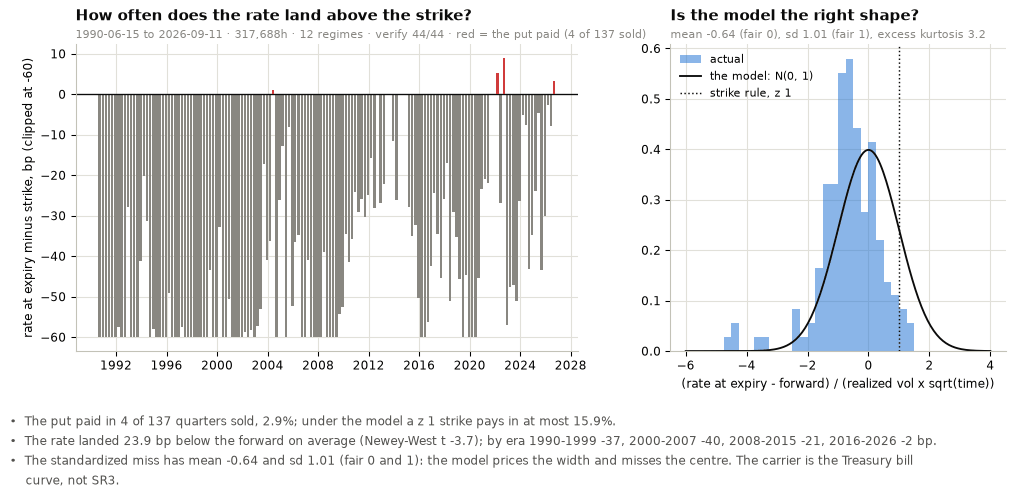

Under the model a z 1 strike pays in at most 15.9% of quarters.

| era | quarters | forward bias, bp | Newey-West t | sd of standardized miss | put paid % |
|---|---|---|---|---|---|
| 1990-1999 | 39 | -37.2 | -5.5 | 0.76 | 0.0 |
| 2000-2007 | 32 | -39.9 | -2.5 | 1.24 | 3.1 |
| 2008-2015 | 32 | -21.1 | -2.4 | 0.82 | 0.0 |
| 2016-2026 | 42 | -1.6 | -0.2 | 1.00 | 7.5 |
| all | 145 | -23.9 | -3.7 | 1.01 | 2.9 |

In [10]:
# ---- where does the rate land against the forward, and is the model the right shape? ----
FB = Q1.R - Q1.F
FB_T = nw_tstat(FB.values)
ZM = Q1.zmiss
KURT = float(((ZM - ZM.mean()) ** 4).mean() / ZM.var() ** 2 - 3)
ERA = [("1990-1999", "1990-01-01", "2000-01-01"), ("2000-2007", "2000-01-01", "2008-01-01"),
       ("2008-2015", "2008-01-01", "2016-01-01"), ("2016-2026", "2016-01-01", "2100-01-01")]
inn = lambda a, b: (Q1.t0 >= a) & (Q1.t0 < b)
E0 = pd.DataFrame({n: {"quarters": inn(a, b).sum(), "forward bias, bp": FB[inn(a, b)].mean(), "Newey-West t": nw_tstat(FB[inn(a, b)].values),
                       "sd of standardized miss": ZM[inn(a, b)].std(), "put paid %": (Q1.pay[inn(a, b) & Q1.traded] > 0).mean() * 100}
                   for n, a, b in ERA}).T
E0.loc["all"] = [len(Q1), FB.mean(), FB_T, ZM.std(), (T1.pay > 0).mean() * 100]
E0.index.name = "era"
N_PAID = int((T1.R > T1.K).sum())
P_MAX = 100 * (1 - float(ncdf(Z)))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [3, 2]})
rk = (T1.R - T1.K)
a0.bar(T1["T"], rk.clip(lower=-60), width=70, color=np.where(rk > 0, C_LOSS, MUTED))
a0.axhline(0, color=INK, lw=1)
a0.set_ylabel("rate at expiry minus strike, bp (clipped at -60)")
ask(a0, "How often does the rate land above the strike?", f"{WINTXT} · red = the put paid ({N_PAID} of {len(T1)} sold)")
bins = np.linspace(-6, 4, 41)
a1.hist(ZM.clip(-6, 4), bins=bins, density=True, color=C_BOOK, alpha=0.55, label="actual")
xs = np.linspace(-6, 4, 200)
a1.plot(xs, npdf(xs), color=INK, lw=1.4, label="the model: N(0, 1)")
a1.axvline(Z, color=INK, ls=":", lw=1.1, label=f"strike rule, z {Z:.0f}")
a1.set_xlabel("(rate at expiry - forward) / (realized vol x sqrt(time))")
a1.legend(loc="upper left", fontsize=8, **LEG)
ask(a1, "Is the model the right shape?", f"mean {ZM.mean():+.2f} (fair 0), sd {ZM.std():.2f} (fair 1), excess kurtosis {KURT:.1f}")
show(fig, "fig:s2-landing", "calibration",
     [f"The put paid in {N_PAID} of {len(T1)} quarters sold, {N_PAID / len(T1) * 100:.1f}%; under the model a z {Z:.0f} strike pays in at most {P_MAX:.1f}%.",
      f"The rate landed {abs(FB.mean()):.1f} bp below the forward on average (Newey-West t {FB_T:.1f}); by era "
      + ", ".join(f"{n} {v:+.0f}" for n, v in E0["forward bias, bp"].iloc[:-1].items()) + " bp.",
      f"The standardized miss has mean {ZM.mean():+.2f} and sd {ZM.std():.2f} (fair 0 and 1): the model prices the width and misses the centre. The carrier is the Treasury bill curve, not SR3."],
     wspace=0.22)
display(Markdown(f"Under the model a z {Z:.0f} strike pays in at most {P_MAX:.1f}% of quarters.\n\n"
                 + mdt(E0, {"quarters": "{:.0f}", "forward bias, bp": "{:+.1f}", "Newey-West t": "{:+.1f}", "sd of standardized miss": "{:.2f}",
                            "put paid %": "{:.1f}"})))

## S3 · Core result

| question | gate to S4 |
|---|---|
| At kappa 1, is there a volatility premium in the short put once the direction is taken out? | the volatility term is positive AND its 95% block-bootstrap interval excludes zero. The total and the mirror are shown and not graded: both are mostly the directional term |

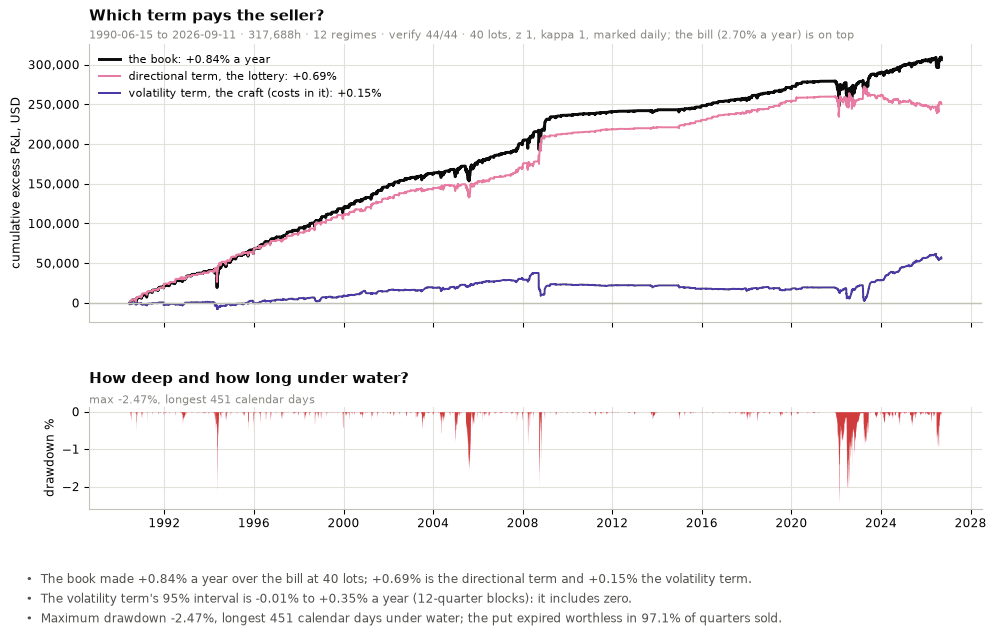

| 40 lots, kappa 1 | ann % | directional ann % | volatility ann % | max DD % | Sharpe | worst day % | worst quarter % | expired worthless % |
|---|---|---|---|---|---|---|---|---|
| short put (the book) | +0.84 | +0.69 | +0.15 | -2.47 | +0.78 | -1.70 | -0.61 | 97.1 |
| short call (the mirror) | -2.38 | -2.69 | +0.31 | -93.11 | -0.76 | -4.40 | -16.54 | 77.0 |

GATE 1: FAIL - volatility term +0.15% a year, 95% interval -0.01% to +0.35% (12-quarter blocks); the total's interval is +0.60% to +1.09%


In [11]:
QC, DC = run(side="call")
M1, MC = score("base", (Q1, D1)), metrics(QC, DC)
VQ = M1["vol term quarterly"]
CI_V = block_ci(VQ, QPY)
CI_T = block_ci(Q1.pnl.values * LOTS / EQUITY, QPY)
TB_ANN = SPOT3.reindex(pd.date_range(WIN_FROM, WIN_TO)).ffill().mean() / 100
tot, dirc = (D1 * LOTS).cumsum(), (Q1.attrs["dir"] * LOTS).cumsum()
eq = EQUITY + tot
uw = (eq / np.maximum(eq.cummax(), EQUITY) - 1) * 100
fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 6.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.1]})
a0.plot(tot.index, tot, color=INK, lw=2.2, label=f"the book: {M1['ann %']:+.2f}% a year")
a0.plot(dirc.index, dirc, color=C_DIR, lw=1.5, label=f"directional term, the lottery: {M1['directional ann %']:+.2f}%")
a0.plot(tot.index, tot - dirc, color=C_VOL, lw=1.5, label=f"volatility term, the craft (costs in it): {M1['volatility ann %']:+.2f}%")
a0.axhline(0, color=AXIS, lw=1.1)
a0.yaxis.set_major_formatter(KFMT); a0.set_ylabel("cumulative excess P&L, USD")
a0.legend(loc="upper left", fontsize=8, **LEG)
ask(a0, "Which term pays the seller?", f"{WINTXT} · {LOTS} lots, z {Z:.0f}, kappa {KAPPA:.0f}, marked daily; the bill ({TB_ANN:.2f}% a year) is on top")
a1.fill_between(uw.index, uw, 0, color=C_LOSS, lw=0)
a1.set_ylabel("drawdown %")
ask(a1, "How deep and how long under water?", f"max {M1['max DD %']:.2f}%, longest {M1['longest under water, days']:,} calendar days")
show(fig, "fig:s3-book", "equity-curve",
     [f"The book made {M1['ann %']:+.2f}% a year over the bill at {LOTS} lots; {M1['directional ann %']:+.2f}% is the directional term and {M1['volatility ann %']:+.2f}% the volatility term.",
      f"The volatility term's 95% interval is {CI_V[0]:+.2f}% to {CI_V[1]:+.2f}% a year ({BLOCK_Q}-quarter blocks): it {'excludes' if CI_V[0] > 0 else 'includes'} zero.",
      f"Maximum drawdown {M1['max DD %']:.2f}%, longest {M1['longest under water, days']:,} calendar days under water; the put expired worthless in {M1['expired worthless %']:.1f}% of quarters sold."],
     hspace=0.45)
T1t = pd.DataFrame({"short put (the book)": M1, "short call (the mirror)": MC}).T
T1t.index.name = f"{LOTS} lots, kappa {KAPPA:.0f}"
c1 = ["ann %", "directional ann %", "volatility ann %", "max DD %", "Sharpe", "worst day %", "worst quarter %", "expired worthless %"]
display(Markdown(mdt(T1t[c1], {c: "{:+.2f}" for c in c1[:7]} | {"expired worthless %": "{:.1f}"})))
G1 = bool(M1["volatility ann %"] > 0 and CI_V[0] > 0)
print(f"GATE 1: {'PASS' if G1 else 'FAIL'} - volatility term {M1['volatility ann %']:+.2f}% a year, 95% interval "
      f"{CI_V[0]:+.2f}% to {CI_V[1]:+.2f}% ({BLOCK_Q}-quarter blocks); the total's interval is {CI_T[0]:+.2f}% to {CI_T[1]:+.2f}%")

## S4 · Robustness

| question | gates to S6 |
|---|---|
| Does the volatility term hold out of sample and after costs, does today's price of vol clear it, does a rule or a hedge buy more per unit of stress, and how much did we try? | volatility term since 2008 > 0; no cost cell turns it negative; break-even kappa (strike held fixed) since 2008 below the low end of today's band; the history-based kappa run keeps it positive. A rule is adopted only if the volatility term per 1% of stress improves AND max drawdown per 1% of stress does not worsen |

In [12]:
split, recent = pd.Timestamp(SPLIT), pd.Timestamp(RECENT)
# ---- the volatility term against kappa, strike held at the kappa-1 rule: one run per kappa, three windows cut from it ----
KSW = np.round(np.arange(0.6, 1.41, 0.05), 2)
WINS = {"full window": None, "since 2008": SPLIT, "since 2016": RECENT}
SW = {w: [] for w in WINS}
for k in KSW:
    QD = run(kappa=k, kstrike=1.0)
    for w, a in WINS.items():
        SW[w].append(metrics(*cut(*QD, a, None))["volatility ann %"])
K_BE = {}
for w, ys in SW.items():
    ys = np.array(ys)
    i = np.where(np.diff(np.sign(ys)) > 0)[0]
    K_BE[w] = float(KSW[i[0]] - ys[i[0]] * (KSW[i[0] + 1] - KSW[i[0]]) / (ys[i[0] + 1] - ys[i[0]])) if len(i) else (np.nan if ys[0] < 0 else KSW[0])

# ---- a historical kappa: MOVE over the realized vol of the 2/5/10/30Y par yields, 2003 on (replaces today's one quote) ----
KMOVE = (MOVE / RV_LONG.reindex(MOVE.index)).rolling(21).median().clip(0.5, 2.5).reindex(DATES).ffill()
QH, DH = run(kappa=1.0, kstrike=1.0, vol=RV63 * KMOVE, start="2003-03-01")
M_H = metrics(QH, DH)

# ---- out of sample, windows the carrier distorts, costs, timing ----
QO = cut(Q1, D1, split, None)
M_O = metrics(*QO)
WF = {z: metrics(*cut(*run(z=z), None, split)) for z in (0.5, 1.0, 1.5)}
for z in WF:
    TRIALS[f"z {z}"] = metrics(*run(z=z))["vol term quarterly"]
Z_IS = max(WF, key=lambda z: WF[z]["Sharpe"])
# the pre-registered break-even (research-001): kappa at which the TOTAL is zero, strike moving with kappa
lo, hi = 0.05, 3.0
for _ in range(25):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if metrics(*run(kappa=mid))["ann %"] < 0 else (lo, mid)
K_BE_TOTAL = 0.5 * (lo + hi)
Q_ex = run(skip=lambda t0, F, s: pd.Timestamp("2008-01-01") <= t0 < pd.Timestamp("2010-01-01"))
Q_zlb = run(skip=lambda t0, F, s: F < 25)
Q_cap = run(vol=RV63.clip(upper=RV63.quantile(0.99)))
CS = {}
keep = SLIP_BP
for sl in (0.125, 0.25, 0.5, 1.0):
    SLIP_BP = sl
    CS[sl] = metrics(*run())["volatility ann %"]
SLIP_BP = keep
OFF = {o: score(f"offset {o}", run(offset=o))["volatility ann %"] for o in (0, 5, 10)}
print(f"S4 runs done: {len(KSW)} kappa runs, 3 z runs, {len(CS)} cost cells, {len(OFF)} entry offsets; break-even kappa of the total {K_BE_TOTAL:.3f}")

S4 runs done: 17 kappa runs, 3 z runs, 4 cost cells, 3 entry offsets; break-even kappa of the total 0.476


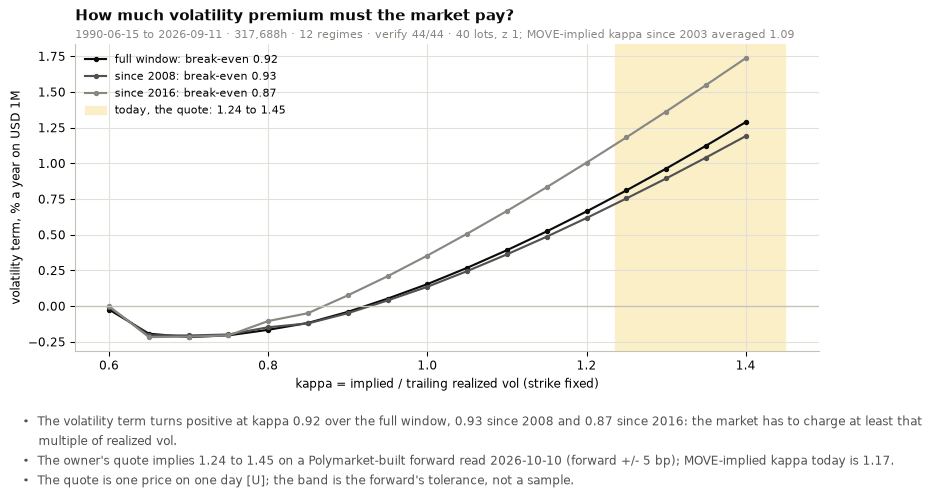

In [13]:
fig, a0 = plt.subplots(1, 1, figsize=(10, 4.6))
for (w, c_) in zip(WINS, (INK, INK2, MUTED)):
    a0.plot(KSW, SW[w], color=c_, marker="o", ms=3, lw=1.6, label=f"{w}: break-even {K_BE[w]:.2f}")
a0.axvspan(min(KAPPA_BAND), max(KAPPA_BAND), color=GOLD, zorder=0, label=f"today, the quote: {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f}")
a0.axhline(0, color=AXIS, lw=1)
a0.set_xlabel("kappa = implied / trailing realized vol (strike fixed)"); a0.set_ylabel("volatility term, % a year on USD 1M")
a0.legend(loc="upper left", fontsize=8, **LEG)
ask(a0, "How much volatility premium must the market pay?", f"{WINTXT} · {LOTS} lots, z {Z:.0f}; MOVE-implied kappa since 2003 averaged {KMOVE[KMOVE.index >= '2003-03-01'].mean():.2f}")
show(fig, "fig:s4-kappa", "cost-sensitivity",
     [f"The volatility term turns positive at kappa {K_BE['full window']:.2f} over the full window, {K_BE['since 2008']:.2f} since 2008 and {K_BE['since 2016']:.2f} since 2016: the market has to charge at least that multiple of realized vol.",
      f"The owner's quote implies {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f} on a Polymarket-built forward read {NOW:%Y-%m-%d} (forward +/- {FWD_TOL_BP:.0f} bp); MOVE-implied kappa today is {KMOVE.iloc[-1]:.2f}.",
      "The quote is one price on one day [U]; the band is the forward's tolerance, not a sample."])

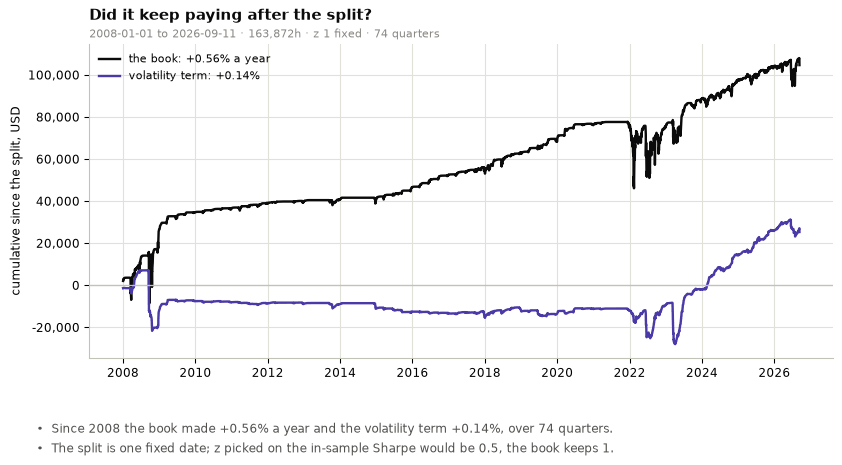

In [14]:
fig, a1 = plt.subplots(1, 1, figsize=(10, 4.6))
po = QO[1] * LOTS
a1.plot(po.index, po.cumsum(), color=INK, lw=1.8, label=f"the book: {M_O['ann %']:+.2f}% a year")
a1.plot(po.index, (po - QO[0].attrs["dir"] * LOTS).cumsum(), color=C_VOL, lw=1.8, label=f"volatility term: {M_O['volatility ann %']:+.2f}%")
a1.axhline(0, color=AXIS, lw=1); a1.yaxis.set_major_formatter(KFMT); a1.set_ylabel("cumulative since the split, USD")
a1.legend(loc="upper left", fontsize=8, **LEG)
ask(a1, "Did it keep paying after the split?", f"{SPLIT} to {WIN_TO:%Y-%m-%d} · {int((WIN_TO - split).days * 24):,}h · z {Z:.0f} fixed · {len(QO[0])} quarters")
show(fig, "fig:s4-oos", "out-of-sample-test",
     [f"Since {SPLIT[:4]} the book made {M_O['ann %']:+.2f}% a year and the volatility term {M_O['volatility ann %']:+.2f}%, over {len(QO[0])} quarters.",
      f"The split is one fixed date; z picked on the in-sample Sharpe would be {Z_IS}, the book keeps {Z:.0f}."])

In [15]:
ET = pd.DataFrame({n: {k: metrics(*cut(Q1, D1, a, b))[k] for k in ("ann %", "directional ann %", "volatility ann %", "max DD %")} for n, a, b in ERA}).T
for lab_, QD in (("ex 2008-09", Q_ex), ("ex zero bound (forward < 25 bp)", Q_zlb), ("realized vol capped at p99", Q_cap), ("MOVE-implied kappa, 2003+", (QH, DH))):
    m = metrics(*QD)
    ET.loc[lab_] = [m[k] for k in ("ann %", "directional ann %", "volatility ann %", "max DD %")]
ET.index.name = f"window, {LOTS} lots"
display(Markdown(mdt(ET, {c: "{:+.2f}" for c in ET.columns})))
T2 = pd.DataFrame({"reading": {
    "z picked on in-sample Sharpe (1990-2007)": f"z {Z_IS}; the book keeps z {Z:g}",
    "slippage 0.125 / 0.25 / 0.5 / 1.0 bp, volatility term": " / ".join(f"{v:+.2f}%" for v in CS.values()),
    "entry 0 / 5 / 10 days after expiry, volatility term": " / ".join(f"{v:+.2f}%" for v in OFF.values()),
    "fair pricing: mean / sd of the standardized miss": f"{ZM.mean():+.2f} / {ZM.std():.2f} (fair 0 / 1)",
    "break-even kappa of the TOTAL, strike moving (pre-registered)": f"{K_BE_TOTAL:.2f}",
    "today's kappa (the quote, forward +/- 5 bp)": f"{KAPPA_TODAY:.2f} ({min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f}); MOVE-implied today {KMOVE.iloc[-1]:.2f}"}})
T2.index.name = "S4"
display(Markdown(mdt(T2)))
G2 = bool(M_O["volatility ann %"] > 0 and min(CS.values()) > 0 and K_BE["since 2008"] < min(KAPPA_BAND) and M_H["volatility ann %"] > 0)
print(f"GATE 2: {'PASS' if G2 else 'FAIL'} - volatility term since {SPLIT[:4]} {M_O['volatility ann %']:+.2f}%, worst cost cell "
      f"{min(CS.values()):+.2f}%, break-even kappa since {SPLIT[:4]} {K_BE['since 2008']:.2f} vs today's low {min(KAPPA_BAND):.2f}, "
      f"MOVE-implied kappa run {M_H['volatility ann %']:+.2f}%")

| window, 40 lots | ann % | directional ann % | volatility ann % | max DD % |
|---|---|---|---|---|
| 1990-1999 | +1.25 | +1.15 | +0.09 | -2.20 |
| 2000-2007 | +1.03 | +0.76 | +0.27 | -1.77 |
| 2008-2015 | +0.58 | +0.74 | -0.16 | -2.40 |
| 2016-2026 | +0.54 | +0.19 | +0.35 | -3.07 |
| ex 2008-09 | +0.76 | +0.59 | +0.17 | -2.53 |
| ex zero bound (forward < 25 bp) | +0.83 | +0.66 | +0.17 | -2.20 |
| realized vol capped at p99 | +0.83 | +0.68 | +0.15 | -2.48 |
| MOVE-implied kappa, 2003+ | +0.77 | +0.46 | +0.30 | -2.57 |

| S4 | reading |
|---|---|
| z picked on in-sample Sharpe (1990-2007) | z 0.5; the book keeps z 1 |
| slippage 0.125 / 0.25 / 0.5 / 1.0 bp, volatility term | +0.20% / +0.15% / +0.06% / -0.13% |
| entry 0 / 5 / 10 days after expiry, volatility term | +0.15% / +0.29% / +0.32% |
| fair pricing: mean / sd of the standardized miss | -0.64 / 1.01 (fair 0 / 1) |
| break-even kappa of the TOTAL, strike moving (pre-registered) | 0.48 |
| today's kappa (the quote, forward +/- 5 bp) | 1.34 (1.24 to 1.45); MOVE-implied today 1.17 |

GATE 2: FAIL - volatility term since 2008 +0.14%, worst cost cell -0.13%, break-even kappa since 2008 0.93 vs today's low 1.24, MOVE-implied kappa run +0.30%


### Rules and hedges

| question | gate |
|---|---|
| Two skip rules and two CME put spreads, each read per unit of stress (the worst loss over the grid) | adopted only if the volatility term per 1% of stress improves AND max drawdown per 1% of stress does not worsen |

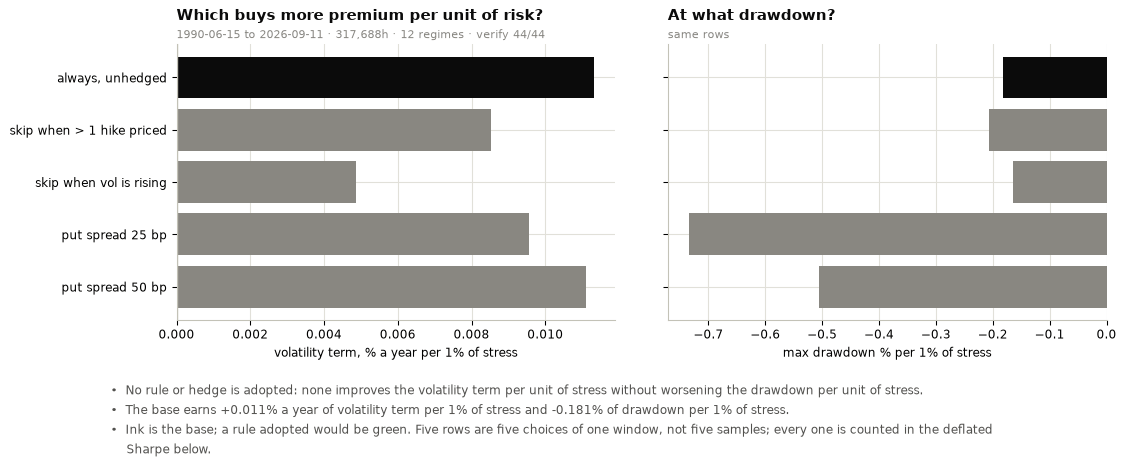

| 40 lots, kappa 1 | ann % | volatility ann % | max DD % | stress % | vol term per 1% stress | max DD per 1% stress | adopted |
|---|---|---|---|---|---|---|---|
| always, unhedged | +0.84 | +0.15 | -2.47 | -13.61 | +0.011 | -0.181 | base |
| skip when > 1 hike priced | +0.39 | +0.12 | -2.82 | -13.61 | +0.009 | -0.207 | no |
| skip when vol is rising | +0.49 | +0.07 | -2.24 | -13.61 | +0.005 | -0.164 | no |
| put spread 25 bp | +0.44 | +0.02 | -1.80 | -2.45 | +0.010 | -0.735 | no |
| put spread 50 bp | +0.63 | +0.05 | -2.51 | -4.95 | +0.011 | -0.506 | no |

GATE 3: nothing adopted; S6 sizes always-sell, unhedged


In [16]:
BASE = (Q1, D1)
VARS = {"always, unhedged": BASE,
        "skip when > 1 hike priced": run(skip=lambda t0, F, s: F - SPOT3.get(t0, F) > 25),
        "skip when vol is rising": run(skip=lambda t0, F, s: RV21.get(t0, 0) > RV63.get(t0, 0)),
        "put spread 25 bp": run(width=25), "put spread 50 bp": run(width=50)}
R3 = {}
for k, QD in VARS.items():
    m = score(k, QD) if k != "always, unhedged" else M1
    st = -m["stress %"]
    R3[k] = {"ann %": m["ann %"], "volatility ann %": m["volatility ann %"], "max DD %": m["max DD %"], "stress %": -st,
             "vol term per 1% stress": m["volatility ann %"] / st, "max DD per 1% stress": m["max DD %"] / st}
T3 = pd.DataFrame(R3).T
T3.index.name = f"{LOTS} lots, kappa {KAPPA:.0f}"
b3 = T3.loc["always, unhedged"]
T3["adopted"] = ["base"] + [("yes" if (r["vol term per 1% stress"] > b3["vol term per 1% stress"] and r["max DD per 1% stress"] >= b3["max DD per 1% stress"]) else "no")
                            for _, r in T3.iloc[1:].iterrows()]
ADOPT = [k for k, v in T3["adopted"].items() if v == "yes"]
BEST = max(ADOPT, key=lambda k: T3.loc[k, "vol term per 1% stress"]) if ADOPT else "always, unhedged"
fig, (a0, a1) = plt.subplots(1, 2, figsize=(12.5, 4.2))
y_ = np.arange(len(T3))
cols_ = [INK] + [C_GOOD if a == "yes" else MUTED for a in T3["adopted"].iloc[1:]]
a0.barh(y_, T3["vol term per 1% stress"], color=cols_)
a0.set_yticks(y_, T3.index); a0.invert_yaxis(); a0.axvline(0, color=AXIS, lw=1)
a0.set_xlabel("volatility term, % a year per 1% of stress")
ask(a0, "Which buys more premium per unit of risk?", WINTXT)
a1.barh(y_, T3["max DD per 1% stress"], color=cols_)
a1.set_yticks(y_, [""] * len(y_)); a1.invert_yaxis()
a1.set_xlabel("max drawdown % per 1% of stress")
ask(a1, "At what drawdown?", "same rows")
show(fig, "fig:s4-rules", "rule-comparison",
     [("Adopted: " + ", ".join(ADOPT) + ".") if ADOPT else "No rule or hedge is adopted: none improves the volatility term per unit of stress without worsening the drawdown per unit of stress.",
      f"The base earns {b3['vol term per 1% stress']:+.3f}% a year of volatility term per 1% of stress and {b3['max DD per 1% stress']:+.3f}% of drawdown per 1% of stress.",
      "Ink is the base; a rule adopted would be green. Five rows are five choices of one window, not five samples; every one is counted in the deflated Sharpe below."],
     wspace=0.12)
display(Markdown(mdt(T3, {c: "{:+.2f}" for c in ("ann %", "volatility ann %", "max DD %", "stress %")}
                     | {"vol term per 1% stress": "{:+.3f}", "max DD per 1% stress": "{:+.3f}"})))
print("GATE 3: " + (f"adopted {', '.join(ADOPT)}; S6 sizes {BEST}" if ADOPT else "nothing adopted; S6 sizes always-sell, unhedged"))

In [17]:
# ---- luck and trials: the bootstrap p of the volatility term, and the deflated Sharpe over every choice scored ----
vq = np.asarray(VQ)
rho = float(np.corrcoef(vq[1:], vq[:-1])[0, 1])
T_EFF = min(len(vq), len(vq) * (1 - rho) / (1 + rho))
sr_q = vq.mean() / vq.std()
uniq = {}
for k, v in TRIALS.items():
    uniq.setdefault(round(float(np.mean(v) / np.std(v)), 6), v)
srs = np.array(list(uniq))
g3 = float(((vq - vq.mean()) ** 3).mean() / vq.std() ** 3)
g4 = float(((vq - vq.mean()) ** 4).mean() / vq.std() ** 4)
N_T, EM = len(srs), 0.5772156649
SR0 = math.sqrt(srs.var()) * ((1 - EM) * ninv(1 - 1 / N_T) + EM * ninv(1 - 1 / (N_T * math.e))) if N_T > 1 else 0.0
DSR = float(ncdf((sr_q - SR0) * math.sqrt(T_EFF - 1) / math.sqrt(max(1 - g3 * sr_q + (g4 - 1) / 4 * sr_q ** 2, 1e-9))))
PSR = float(ST.psr(list(VQ)))
LUCK = ST.bootstrap_p_one_sided(VQ, BLOCK_Q, NBOOT, RNG)
print(f"volatility term per quarter: probabilistic Sharpe {PSR:.2f} above zero, deflated Sharpe {DSR:.2f} over {N_T} distinct choices "
      f"({T_EFF:.0f} effective quarters); one-sided bootstrap p of the term above zero {LUCK['p']:.3f}")

volatility term per quarter: probabilistic Sharpe 0.87 above zero, deflated Sharpe 0.23 over 9 distinct choices (145 effective quarters); one-sided bootstrap p of the term above zero 0.052


## S5 · Risk and diagnostics

| question | answer form |
|---|---|
| How bad do the tails get in the history, and how bad does the trade as sent get on today's Polymarket prices? | the quarters the put paid and the tail statistics; the 27 outcome rows, the paths they leave out, the January and level hedges |

### S5.1 · The tail in the history

In [18]:
PAID = T1[T1.R > T1.K].copy()
PT = pd.DataFrame({"strike %": PAID.K / 100, "settle %": PAID.R / 100, "premium bp": PAID.prem, "payout bp": PAID.pay,
                   f"P&L USD at {LOTS} lots": PAID.pnl * LOTS}).set_index(PAID["T"].dt.strftime("%Y-%m-%d"))
PT.index.name = "expiry"
TS = ST.tail_stats(list(Q1.loc[Q1.traded, "pnl"] * LOTS / EQUITY * 100))
display(Markdown(f"**The {len(PT)} quarters the put paid out:**\n\n" + mdt(PT, {"strike %": "{:.3f}", "settle %": "{:.3f}", "premium bp": "{:.1f}", "payout bp": "{:.1f}", f"P&L USD at {LOTS} lots": "{:,.0f}"})
                 + f"\n\nQuarterly P&L on equity: VaR 95% {TS['VaR 95%']:+.2f}%, CVaR 95% {TS['CVaR 95%']:+.2f}%, skew {TS['skew']:+.2f}, "
                 f"kurtosis {TS['kurtosis']:.1f}, worst {TS['worst']:+.2f}%; the stress grid (forward against the book on entry day, vol x 1.5) "
                 f"loses {-M1['stress %']:.2f}% of equity at its worst."))

**The 4 quarters the put paid out:**

| expiry | strike % | settle % | premium bp | payout bp | P&L USD at 40 lots |
|---|---|---|---|---|---|
| 2004-06-10 | 1.312 | 1.323 | 1.2 | 1.1 | -427 |
| 2022-03-11 | 0.375 | 0.428 | 1.0 | 5.3 | -4,801 |
| 2022-09-16 | 3.125 | 3.214 | 3.4 | 8.9 | -6,126 |
| 2026-09-11 | 4.000 | 4.033 | 1.6 | 3.3 | -2,253 |

Quarterly P&L on equity: VaR 95% +0.03%, CVaR 95% -0.18%, skew +0.52, kurtosis 11.2, worst -0.61%; the stress grid (forward against the book on entry day, vol x 1.5) loses 13.61% of equity at its worst.

### S5.2 · The trade as sent, on today's prices

| question | how it is answered |
|---|---|
| Is the math right? | the 27 rows rebuilt from the contract rules (the screenshot did not reach the session: compare row by row) |
| How to hedge January, at what cost? | Polymarket's January contract and its rate-level markets walked on their live books, beside CME puts priced at the quote's own implied vol |
| What does the table miss? | 75 bp moves, the option expiring before January, cuts, the SOFR basis, margin |

This section is a LIVE read: it prices the owner's trade on Polymarket's books at the moment the notebook runs and moves every run. The record
of the 2026-09-27 read, from this notebook's own saved output, sits beside the new one at the end of the section.

In [19]:
# ---- the 27 paths, as the option settles on 11 Dec: Oct and Dec DECIDED, January PRICED ----
HIKE50 = {m: PX[(m, "50+ bps increase")] for m in MEET}
book = {m: PM.book(HIKE50[m]["token_ids"][0]) for m in MEET}


def walk(bk, n, row, cap=WALK_CAP):
    # fill n YES up the ask ladder, no level above `cap`: (filled, average price, fee USD from the market's own fee fields)
    left, cost, fee = n, 0.0, 0.0
    for px, sz in bk["asks"]:
        if px > cap:
            break
        q = min(left, sz)
        cost += q * px
        fee += MATCH.pm_taker_fee(px, row.get("fee_rate"), row.get("fee_exponent"), row.get("fees_enabled"), contracts=q) or 0.0
        left -= q
        if left <= 0:
            break
    got = n - max(left, 0)
    return got, (cost / got if got else float("nan")), fee


EXE = {m: walk(book[m], OWN_YES, HIKE50[m]) for m in ("Oct", "Dec")}
HEDGE_EXEC = sum(g * p + f for g, p, f in EXE.values())
PREM_EXEC = OWN_PREM_USD - OWN_LOTS * (FEE_OPT + SLIP_BP * USD_PER_BP)
EXER = OWN_LOTS * (FEE_FUT + SLIP_FUT_BP * USD_PER_BP)
KEYW = {0: "No change", 25: "25 bps increase", 50: "50+ bps increase"}
settle = lambda o, d, jp: SOFR_BP + o + d + WJ * jp


def net_exec(o, d, jp):
    R = settle(o, d, jp)
    loss = OWN_LOTS * USD_PER_BP * max(R - K_OWN, 0.0) + (EXER if R > K_OWN else 0.0)
    return PREM_EXEC - loss + OWN_YES * ((o >= 50) + (d >= 50)) - HEDGE_EXEC


P9 = pd.DataFrame([{"Oct / Dec decided": f"{o} / {d}", "P %": PN["Oct"][KEYW[o]] * PN["Dec"][KEYW[d]] * 100,
                    "YES paid USD": OWN_YES * ((o >= 50) + (d >= 50)),
                    **{f"net, Jan priced +{jp}": net_exec(o, d, jp) for jp in (0, 25, 50)}}
                   for o in (0, 25, 50) for d in (0, 25, 50)]).set_index("Oct / Dec decided")
display(Markdown(f"The 27 rows at executable prices, read {NOW:%Y-%m-%d %H:%MZ} (premium after CME fee and one tick; YES at Polymarket's live asks plus its fee; "
                 "futures fee on exercise). P multiplies the two meetings as if independent [U].\n\n"
                 + mdt(P9, {"P %": "{:.1f}", "YES paid USD": "{:,.0f}", **{c: "{:,.0f}" for c in P9.columns if c.startswith("net")}})))
cells = P9[[c for c in P9.columns if c.startswith("net")]]
WORST27 = (cells.stack().idxmin(), cells.stack().min())
MODAL = P9["P %"].idxmax()
ARITH_OK = all(abs(a - b) < 1 for a, b in ((OWN_LOTS * QUOTE_BP * USD_PER_BP, OWN_PREM_USD),
                                           (2 * OWN_YES * OWN_YES_PX, OWN_HEDGE_USD), (OWN_LOTS * USD_PER_BP, 1000.0)))

The 27 rows at executable prices, read 2026-10-10 09:41Z (premium after CME fee and one tick; YES at Polymarket's live asks plus its fee; futures fee on exercise). P multiplies the two meetings as if independent [U].

| Oct / Dec decided | P % | YES paid USD | net, Jan priced +0 | net, Jan priced +25 | net, Jan priced +50 |
|---|---|---|---|---|---|
| 0 / 0 | 18.5 | 0 | 1,890 | 1,890 | 1,890 |
| 0 / 25 | 61.3 | 0 | 1,890 | 1,890 | 1,890 |
| 0 / 50 | 2.4 | 22,013 | 23,903 | 23,903 | 16,480 |
| 25 / 0 | 3.4 | 0 | 1,890 | 1,890 | 1,890 |
| 25 / 25 | 11.4 | 0 | 1,890 | 1,890 | -5,533 |
| 25 / 50 | 0.5 | 22,013 | 17,853 | 4,667 | -8,520 |
| 50 / 0 | 0.1 | 22,013 | 23,903 | 23,903 | 16,480 |
| 50 / 25 | 0.3 | 22,013 | 17,853 | 4,667 | -8,520 |
| 50 / 50 | 0.0 | 44,026 | 14,866 | 1,680 | -11,507 |

| scenario (Oct / Dec / Jan priced) | Z26 at expiry % | YES paid USD | net USD | why it matters |
|---|---|---|---|---|
| -25 / -25 / -25 | 3.238 | 0 | 1,890 | cuts: the puts expire, the YES cost is lost |
| 75 / 25 / 0 | 4.870 | 22,013 | -7,147 | a 75 bp hike: '50+' pays the same USD 1, the puts lose 25 bp more |
| 75 / 75 / +50 | 5.634 | 44,026 | -61,507 | a 2022-style run: the loss is linear, the hedge is capped |
| 50 / 50 / +100 | 5.397 | 44,026 | -37,881 | two 50s and a market pricing more on 11 Dec |

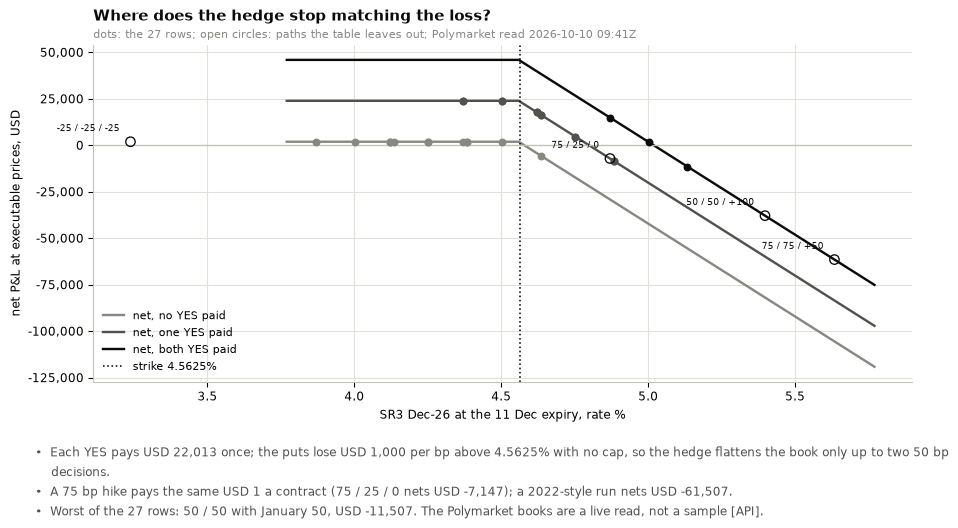

In [20]:
# ---- what the 27 rows leave out ----
X = []
for name, o, d, jp, note in (("-25 / -25 / -25", -25, -25, -25, "cuts: the puts expire, the YES cost is lost"),
                              ("75 / 25 / 0", 75, 25, 0, "a 75 bp hike: '50+' pays the same USD 1, the puts lose 25 bp more"),
                              ("75 / 75 / +50", 75, 75, 50, "a 2022-style run: the loss is linear, the hedge is capped"),
                              ("50 / 50 / +100", 50, 50, 100, "two 50s and a market pricing more on 11 Dec")):
    X.append({"scenario (Oct / Dec / Jan priced)": name, "Z26 at expiry %": settle(o, d, jp) / 100,
              "YES paid USD": OWN_YES * ((o >= 50) + (d >= 50)), "net USD": net_exec(o, d, jp), "why it matters": note})
XT = pd.DataFrame(X).set_index("scenario (Oct / Dec / Jan priced)")
display(Markdown(mdt(XT, {"Z26 at expiry %": "{:.3f}", "YES paid USD": "{:,.0f}", "net USD": "{:,.0f}"})))

fig, ax = plt.subplots(figsize=(11, 5))
xr = np.linspace(SOFR_BP - 10, SOFR_BP + 190, 300)
puts = PREM_EXEC - OWN_LOTS * USD_PER_BP * np.maximum(xr - K_OWN, 0) - np.where(xr > K_OWN, EXER, 0)
for n_, c_, lab in ((0, MUTED, "no YES paid"), (1, INK2, "one YES paid"), (2, INK, "both YES paid")):
    ax.plot(xr / 100, puts + n_ * OWN_YES - HEDGE_EXEC, color=c_, lw=1.8, label=f"net, {lab}")
    for o in (0, 25, 50):
        for d in (0, 25, 50):
            if (o >= 50) + (d >= 50) == n_:
                ax.scatter([settle(o, d, jp) / 100 for jp in (0, 25, 50)], [net_exec(o, d, jp) for jp in (0, 25, 50)], color=c_, s=24, zorder=5)
for nm, r in XT.iterrows():
    ax.annotate(nm, (r["Z26 at expiry %"], r["net USD"]), textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=7, color=INK)
    ax.scatter([r["Z26 at expiry %"]], [r["net USD"]], facecolors="none", edgecolors=INK, s=50, zorder=6)
ax.axvline(K_OWN / 100, color=INK, ls=":", lw=1.2, label=f"strike {K_OWN / 100:.4f}%")
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(KFMT)
ax.set_xlabel("SR3 Dec-26 at the 11 Dec expiry, rate %"); ax.set_ylabel("net P&L at executable prices, USD")
ax.legend(loc="lower left", fontsize=8, **LEG)
ask(ax, "Where does the hedge stop matching the loss?",
    f"dots: the 27 rows; open circles: paths the table leaves out; Polymarket read {NOW:%Y-%m-%d %H:%MZ}")
show(fig, "fig:s5-as-sent", "scenario-payoff",
     [f"Each YES pays {usd(OWN_YES)} once; the puts lose {usd(OWN_LOTS * USD_PER_BP)} per bp above {K_OWN / 100:.4f}% with no cap, so the hedge flattens the book only up to two 50 bp decisions.",
      f"A 75 bp hike pays the same USD 1 a contract (75 / 25 / 0 nets {usd(XT.loc['75 / 25 / 0', 'net USD'])}); a 2022-style run nets {usd(XT.loc['75 / 75 / +50', 'net USD'])}.",
      f"Worst of the 27 rows: {WORST27[0][0]} with January {WORST27[0][1].split('+')[1]}, {usd(WORST27[1])}. The Polymarket books are a live read, not a sample [API]."],
     window_re=WIN_STAMP)

In [21]:
# ---- hedging January and the level: Polymarket's January contract, its rate-level strip, and CME puts ----
N_JAN = int(round(OWN_LOTS * USD_PER_BP * 50 * WJ))          # 40 lots x USD 25 x 50 bp x January's weight
gotJ, pxJ, feeJ = walk(book["Jan"], N_JAN, HIKE50["Jan"])
# the level strip: "hit X% before 2027" pays if the upper bound reaches X by the December decision, i.e. before the 11 Dec expiry
LV = {}
for mk in LEVEL_EV["markets"]:
    r = PM.parse_market(mk, LEVEL_EV)
    t = str(r["group_item_title"]).strip()
    if t.startswith("\u2191") and not r.get("closed"):
        LV[float(t.lstrip("\u2191 ").rstrip("%"))] = r
loss_at = lambda u: OWN_LOTS * USD_PER_BP * max(SOFR_BP + (u - UPPER0_PCT) * 100 - K_OWN, 0.0)
rungs = sorted(u for u in LV if loss_at(u) > 0)
STRIP, prev = [], 0.0
for u in rungs:
    n = int(round(loss_at(u) - prev))
    prev = loss_at(u)
    g, p, f = walk(PM.book(LV[u]["token_ids"][0]), n, LV[u])
    STRIP.append({"level": u, "contracts": n, "filled": g, "avg": p, "cost": g * p + f})
STRIP = pd.DataFrame(STRIP)
S_LO, S_HI = (implied_s(QUOTE_BP, F_Z26 + dF, K_OWN, "put") for dF in (FWD_TOL_BP, -FWD_TOL_BP))
JH = [{"hedge": f"Polymarket January '50+ bps increase' x {N_JAN:,}", "cost USD": gotJ * pxJ + feeJ, "cost over fwd band": "-",
       "filled below cap %": gotJ / N_JAN * 100, "worst loss left USD": np.nan},
      {"hedge": f"Polymarket 'hit {min(rungs):.2f}% ... {max(rungs):.2f}% before 2027' strip", "cost USD": STRIP.cost.sum(), "cost over fwd band": "-",
       "filled below cap %": STRIP.filled.sum() / STRIP.contracts.sum() * 100, "worst loss left USD": np.nan}]
for w in (6.25, 12.5, 18.75, 25.0):
    k2 = K_OWN + w
    cst = lambda s_: OWN_LOTS * USD_PER_BP * float(bach(F_Z26, k2, s_, "put")) + OWN_LOTS * (FEE_OPT + SLIP_BP * USD_PER_BP)
    c_mid = cst(SIG_TODAY * math.sqrt(TAU_Z26))
    JH.append({"hedge": f"buy 40 Dec-26 {100 - k2 / 100:.4f} puts", "cost USD": c_mid,
               "cost over fwd band": f"{cst(S_LO):,.0f} to {cst(S_HI):,.0f}", "filled below cap %": np.nan,
               "worst loss left USD": OWN_LOTS * USD_PER_BP * w + EXER - (PREM_EXEC - c_mid)})
JHT = pd.DataFrame(JH).set_index("hedge")
CME = JHT.iloc[2:]
REC = CME[CME["cost USD"] <= 0.5 * PREM_EXEC]["worst loss left USD"].idxmin()
REC_W = abs((100 - float(REC.split()[3])) * 100 - K_OWN)
display(Markdown(
    f"January size N = {OWN_LOTS} lots x USD {USD_PER_BP:.0f} x 50 bp x {WJ:.3f}; it pays on one decision on 27 Jan, after the 11 Dec expiry, "
    "so it works only if sold on 11 Dec at whatever January is priced (exit at the bid, untested [U]). The level strip buys, at each "
    f"'hit X%' rung, the extra USD the puts lose between rungs (upper bound {UPPER0_PCT:.2f}% today, SOFR {SOFR0_PCT:.2f}%, January priced 0): "
    f"it follows the loss up to {max(rungs):.2f}% and pays on the December level, before expiry. CME puts: Bachelier at the quote's "
    "implied vol, no skew, so a LOWER BOUND on cost [U]. Pick rule for the CME put: the smallest worst loss among puts costing at "
    f"most half the premium. Asks walked up to {WALK_CAP:.2f} [API].\n\n"
    + mdt(JHT, {"cost USD": "{:,.0f}", "filled below cap %": "{:.0f}", "worst loss left USD": "{:,.0f}"})
    + "\n\n" + mdt(STRIP.set_index("level").rename_axis("hit level %"), {"contracts": "{:,.0f}", "filled": "{:,.0f}", "avg": "{:.3f}", "cost": "{:,.0f}"})))

January size N = 40 lots x USD 25 x 50 bp x 0.527; it pays on one decision on 27 Jan, after the 11 Dec expiry, so it works only if sold on 11 Dec at whatever January is priced (exit at the bid, untested [U]). The level strip buys, at each 'hit X%' rung, the extra USD the puts lose between rungs (upper bound 4.00% today, SOFR 3.87%, January priced 0): it follows the loss up to 5.50% and pays on the December level, before expiry. CME puts: Bachelier at the quote's implied vol, no skew, so a LOWER BOUND on cost [U]. Pick rule for the CME put: the smallest worst loss among puts costing at most half the premium. Asks walked up to 0.20 [API].

| hedge | cost USD | cost over fwd band | filled below cap % | worst loss left USD |
|---|---|---|---|---|
| Polymarket January '50+ bps increase' x 26,374 | 869 | - | 56 | - |
| Polymarket 'hit 4.75% ... 5.50% before 2027' strip | 1,573 | - | 38 | - |
| buy 40 Dec-26 95.3750 puts | 2,480 | 1,900 to 3,118 | - | 6,316 |
| buy 40 Dec-26 95.3125 puts | 1,862 | 1,396 to 2,391 | - | 11,947 |
| buy 40 Dec-26 95.2500 puts | 1,397 | 1,032 to 1,827 | - | 17,732 |
| buy 40 Dec-26 95.1875 puts | 1,054 | 776 to 1,395 | - | 23,640 |

| hit level % | contracts | filled | avg | cost |
|---|---|---|---|---|
| 4.75 | 5,750 | 553 | 0.113 | 65 |
| 5.0 | 25,000 | 25,000 | 0.051 | 1,335 |
| 5.25 | 25,000 | 587 | 0.039 | 24 |
| 5.5 | 25,000 | 4,549 | 0.031 | 149 |

In [22]:
# ---- the 2026-09-27 read of this section: typed from this notebook's own saved output (run 2026-09-27 13:31Z), NOT re-read [1] ----
REC0927 = {"SOFR %, newest value": 3.88, "Fed upper bound %": 4.00, "premium after fee and tick, USD": 2714, "YES cost at live asks, USD": 1515,
           "December YES average price, c": 5.7, "December best ask size": 595, "worst of the 27 rows, USD": -13198, "75 / 25 / 0, USD": -8838,
           "75 / 75 / +50, USD": -63198, "50 / 50 / +100, USD": -39572, "implied vol of the quote, bp/yr": 71, "kappa of the quote, low": 0.95, "kappa of the quote, high": 1.17,
           "CME put picked": "95.2500", "its cost, USD": 1183, "worst loss left, USD": 17518, "October fill, %": 100, "December fill, %": 100, "January fill, %": 12}
NOWV = {"SOFR %, newest value": SOFR0_PCT, "Fed upper bound %": UPPER0_PCT, "premium after fee and tick, USD": PREM_EXEC, "YES cost at live asks, USD": HEDGE_EXEC,
        "December YES average price, c": EXE["Dec"][1] * 100, "December best ask size": book["Dec"]["asks"][0][1], "worst of the 27 rows, USD": WORST27[1],
        "75 / 25 / 0, USD": XT.loc["75 / 25 / 0", "net USD"], "75 / 75 / +50, USD": XT.loc["75 / 75 / +50", "net USD"], "50 / 50 / +100, USD": XT.loc["50 / 50 / +100", "net USD"],
        "implied vol of the quote, bp/yr": SIG_TODAY, "kappa of the quote, low": min(KAPPA_BAND), "kappa of the quote, high": max(KAPPA_BAND),
        "CME put picked": REC.split()[3], "its cost, USD": JHT.loc[REC, "cost USD"], "worst loss left, USD": JHT.loc[REC, "worst loss left USD"],
        "October fill, %": walk(book["Oct"], OWN_YES, HIKE50["Oct"])[0] / OWN_YES * 100, "December fill, %": walk(book["Dec"], OWN_YES, HIKE50["Dec"])[0] / OWN_YES * 100,
        "January fill, %": gotJ / N_JAN * 100}
fm = lambda v: v if isinstance(v, str) else (f"{v:,.2f}" if abs(v) < 10 else f"{v:,.0f}")
CMP = pd.DataFrame({"2026-09-27 read (saved output) [1]": {k: fm(v) for k, v in REC0927.items()},
                    f"this run, {NOW:%Y-%m-%d %H:%MZ} [API]": {k: fm(NOWV[k]) for k in REC0927}})
CMP.index.name = "the trade as sent"
display(Markdown("**The trade as sent, then and now.** The left column is typed from the notebook's saved output of 2026-09-27 (its SOFR is the NY Fed value of 2026-09-24) and is not re-read; "
                 "the right column is this run's live read. A difference is the market moving, not a correction.\n\n" + mdt(CMP)))

# ---- Part A, answered: biggest risk first ----
A = [
    f"**You lose when the Fed goes faster than 25 a meeting, and that is where the hedge runs out.** Each YES pays "
    f"{usd(OWN_YES)} once; the puts lose {usd(OWN_LOTS * USD_PER_BP)} per bp above {K_OWN / 100:.4f}%, with no cap. "
    f"A 75 bp hike pays the same USD 1 a contract (75 / 25 / 0 nets {usd(XT.loc['75 / 25 / 0', 'net USD'])}); a 2022-style "
    f"run nets {usd(XT.loc['75 / 75 / +50', 'net USD'])}.",
    f"**The puts settle on {Z26[0]:%d %b}, before January is decided.** What counts is how much January the market *prices* that "
    f"day, at weight {WJ:.2f}. Two 50s and a market pricing +100 for January nets {usd(XT.loc['50 / 50 / +100', 'net USD'])}.",
    f"**The arithmetic {'checks' if ARITH_OK else 'does NOT check'}; live prices shrink it.** {usd(OWN_PREM_USD)} premium, "
    f"{usd(OWN_HEDGE_USD)} of YES and {usd(OWN_LOTS * USD_PER_BP)} per bp are right at mid. Executable: premium {usd(PREM_EXEC)}, "
    f"YES {usd(HEDGE_EXEC)} (December's book shows {book['Dec']['asks'][0][1]:,.0f} at the best ask, so {OWN_YES:,} average "
    f"{EXE['Dec'][1] * 100:.1f}c, not {OWN_YES_PX * 100:.1f}c). Worst of the 27 rows: {WORST27[0][0]} with January {WORST27[0][1].split('+')[1]}, {usd(WORST27[1])}.",
    f"**January: Polymarket's books are too thin to hedge the meeting or the level.** The January '50+' pays on "
    f"27 Jan, after the puts settle, and only {JHT.iloc[0]['filled below cap %']:.0f}% of {N_JAN:,} is offered below {WALK_CAP:.2f}. "
    f"The 'hit X% before 2027' markets pay on the December level, before expiry (the right shape), but only "
    f"{JHT.iloc[1]['filled below cap %']:.0f}% of the strip to {max(rungs):.2f}% is offered below {WALK_CAP:.2f}. The cap that fills is "
    f"CME: 40 Dec-26 {REC.split()[3]} puts ({usd(JHT.loc[REC, 'cost USD'])}) make the book a {REC_W:.2f} bp put spread, worst loss "
    f"{usd(JHT.loc[REC, 'worst loss left USD'])} [U, no skew].",
    "**Also missing:** daily CME margin on a short option; SOFR drifting in its range (the year-end turn falls inside the "
    "reference quarter, and each bp is USD 1,000 on an in-the-money row); and meetings that are not independent, so the joint hike "
    "tail is fatter than the product of these prices. Cuts are harmless: the puts expire and the YES cost is lost.",
]
display(Markdown("### The trade as sent: the answer\n\n" + "\n".join(f"{i + 1}. {a}" for i, a in enumerate(A))))

**The trade as sent, then and now.** The left column is typed from the notebook's saved output of 2026-09-27 (its SOFR is the NY Fed value of 2026-09-24) and is not re-read; the right column is this run's live read. A difference is the market moving, not a correction.

| the trade as sent | 2026-09-27 read (saved output) [1] | this run, 2026-10-10 09:41Z [API] |
|---|---|---|
| SOFR %, newest value | 3.88 | 3.87 |
| Fed upper bound % | 4.00 | 4.00 |
| premium after fee and tick, USD | 2,714 | 2,714 |
| YES cost at live asks, USD | 1,515 | 824 |
| December YES average price, c | 5.70 | 3.17 |
| December best ask size | 595 | 637 |
| worst of the 27 rows, USD | -13,198 | -11,507 |
| 75 / 25 / 0, USD | -8,838 | -7,147 |
| 75 / 75 / +50, USD | -63,198 | -61,507 |
| 50 / 50 / +100, USD | -39,572 | -37,881 |
| implied vol of the quote, bp/yr | 71 | 97 |
| kappa of the quote, low | 0.95 | 1.24 |
| kappa of the quote, high | 1.17 | 1.45 |
| CME put picked | 95.2500 | 95.1875 |
| its cost, USD | 1,183 | 1,054 |
| worst loss left, USD | 17,518 | 23,640 |
| October fill, % | 100 | 100 |
| December fill, % | 100 | 100 |
| January fill, % | 12 | 56 |

### The trade as sent: the answer

1. **You lose when the Fed goes faster than 25 a meeting, and that is where the hedge runs out.** Each YES pays USD 22,013 once; the puts lose USD 1,000 per bp above 4.5625%, with no cap. A 75 bp hike pays the same USD 1 a contract (75 / 25 / 0 nets USD -7,147); a 2022-style run nets USD -61,507.
2. **The puts settle on 11 Dec, before January is decided.** What counts is how much January the market *prices* that day, at weight 0.53. Two 50s and a market pricing +100 for January nets USD -37,881.
3. **The arithmetic checks; live prices shrink it.** USD 3,000 premium, USD 660 of YES and USD 1,000 per bp are right at mid. Executable: premium USD 2,714, YES USD 824 (December's book shows 637 at the best ask, so 22,013 average 3.2c, not 1.5c). Worst of the 27 rows: 50 / 50 with January 50, USD -11,507.
4. **January: Polymarket's books are too thin to hedge the meeting or the level.** The January '50+' pays on 27 Jan, after the puts settle, and only 56% of 26,374 is offered below 0.20. The 'hit X% before 2027' markets pay on the December level, before expiry (the right shape), but only 38% of the strip to 5.50% is offered below 0.20. The cap that fills is CME: 40 Dec-26 95.1875 puts (USD 1,054) make the book a 25.00 bp put spread, worst loss USD 23,640 [U, no skew].
5. **Also missing:** daily CME margin on a short option; SOFR drifting in its range (the year-end turn falls inside the reference quarter, and each bp is USD 1,000 on an in-the-money row); and meetings that are not independent, so the joint hike tail is fatter than the product of these prices. Cuts are harmless: the puts expire and the YES cost is lost.

## S6 · Decision

| question | decision rule |
|---|---|
| How many lots per USD 1M, and does each leg of the owner's hedge fill near the assumed 1.5c? | sizing: the most lots whose max drawdown stays inside the desk limit AND whose worst stress-grid loss stays under the stress limit, solved, not read off a ladder; information only unless gates 1 and 2 pass. Hedge: each leg fills fully within 0.5c of the assumed price |

### S6.1 · Sizing, last

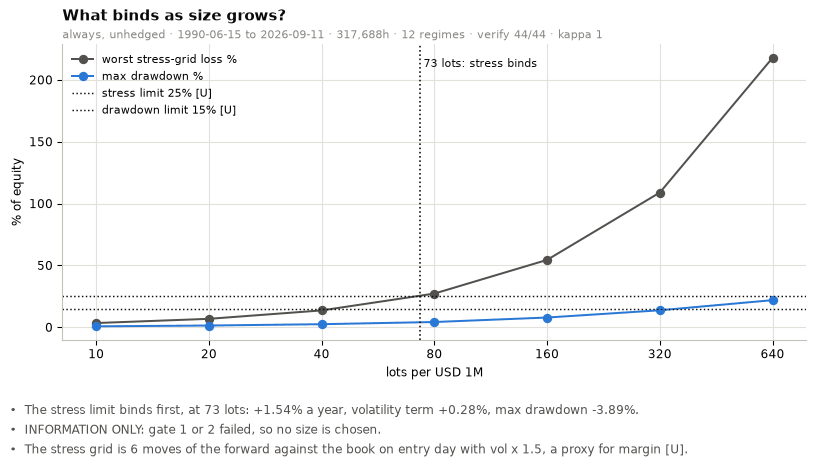

S6.1: 73 lots (always, unhedged) - stress binds; +1.54% a year, volatility term +0.28%, max drawdown -3.89%. INFORMATION ONLY: gate 1 or 2 failed, NO SIZE


In [23]:
Q4, D4 = VARS[BEST]
s_lot = stress_lot(Q4)
N_STRESS = STRESS_LIMIT_PCT / 100 * EQUITY / s_lot
lo, hi = 1.0, 5000.0
for _ in range(40):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if metrics(Q4, D4, lots=mid)["max DD %"] > -DD_LIMIT_PCT else (lo, mid)
N_DD = lo
PICK = int(math.floor(min(N_STRESS, N_DD)))
BIND = "stress" if N_STRESS < N_DD else "drawdown"
LN = np.array([10, 20, 40, 80, 160, 320, 640])
LM = {n: metrics(Q4, D4, lots=n) for n in LN}
M4 = metrics(Q4, D4, lots=PICK)
SIZED = G1 and G2
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(LN, [-LM[n]["stress %"] for n in LN], color=INK2, marker="o", label="worst stress-grid loss %")
ax.plot(LN, [-LM[n]["max DD %"] for n in LN], color=C_BOOK, marker="o", label="max drawdown %")
ax.axhline(STRESS_LIMIT_PCT, color=INK, ls=":", lw=1.1, label=f"stress limit {STRESS_LIMIT_PCT:.0f}% [U]")
ax.axhline(DD_LIMIT_PCT, color=INK, ls=":", lw=1.1, label=f"drawdown limit {DD_LIMIT_PCT:.0f}% [U]")
ax.axvline(PICK, color=INK, ls=":", lw=1.2)
ax.text(PICK, ax.get_ylim()[1] * 0.92, f" {PICK} lots: {BIND} binds", fontsize=8, color=INK)
ax.set_xscale("log", base=2); ax.set_xticks(LN, [str(n) for n in LN])
ax.set_xlabel("lots per USD 1M"); ax.set_ylabel("% of equity"); ax.legend(loc="upper left", fontsize=8, **LEG)
ask(ax, "What binds as size grows?", f"{BEST} · {WINTXT} · kappa {KAPPA:.0f}")
show(fig, "fig:s6-size", "sizing-and-fill",
     [f"The {BIND} limit binds first, at {PICK} lots: {M4['ann %']:+.2f}% a year, volatility term {M4['volatility ann %']:+.2f}%, max drawdown {M4['max DD %']:.2f}%.",
      ("Sized: gates 1 and 2 passed." if SIZED else "INFORMATION ONLY: gate 1 or 2 failed, so no size is chosen."),
      f"The stress grid is {len(STRESS_GRID)} moves of the forward against the book on entry day with vol x 1.5, a proxy for margin [U]."])
print(f"S6.1: {PICK} lots ({BEST}) - {BIND} binds; {M4['ann %']:+.2f}% a year, volatility term {M4['volatility ann %']:+.2f}%, "
      f"max drawdown {M4['max DD %']:.2f}%" + ("" if SIZED else ". INFORMATION ONLY: gate 1 or 2 failed, NO SIZE"))

### S6.2 · Execution: the prediction-market hedge on resolved markets and on live books

In [24]:
EV, cur, pages = [], None, 0
while pages < 90:
    pg = PM.events_keyset_raw(limit=100, cursor=cur, order="volume", ascending=False, closed=True)
    EV += [e for e in pg.get("events") or [] if (e.get("title") or "").lower().startswith(("fed decision in", "fed interest rates:"))]
    cur, pages = pg.get("next_cursor"), pages + 1
    if not cur:
        break
PMR = []
for e in EV:
    for mk in e.get("markets") or []:
        r = PM.parse_market(mk, e)
        if not r.get("token_ids") or not r.get("close_ts") or not r.get("outcome_prices"):
            continue
        h = PM.history(r["token_ids"][0], days=40, fidelity=1440, end_s=int(r["close_ts"] // 1000))
        hs = pd.Series({x["t"]: x["p"] for x in h}, dtype=float)
        cut30 = r["close_ts"] - 30 * 86_400_000
        p30 = hs[hs.index <= cut30].iloc[-1] if (hs.index <= cut30).any() else np.nan
        PMR.append({"close": pd.Timestamp(r["close_ts"], unit="ms").normalize(), "outcome": r["group_item_title"],
                    "won": float(r["outcome_prices"][0]) == 1.0, "p30": p30,
                    "fee today": MATCH.pm_taker_fee(p30, r.get("fee_rate"), r.get("fee_exponent"), r.get("fees_enabled"), contracts=OWN_YES)
                    if np.isfinite(p30) else np.nan})
PMR = pd.DataFrame(PMR)
N_EV = PMR.close.nunique()
bins = [0, 0.02, 0.05, 0.15, 0.5, 0.85, 0.95, 1.0001]
PMR["bucket"] = pd.cut(PMR.p30, bins, right=False)
CAL30 = PMR.dropna(subset=["p30"]).groupby("bucket", observed=True).agg(outcomes=("won", "size"), mean_price=("p30", "mean"), won_share=("won", "mean"))
CAL30.index = [f"{iv.left:.2f} to {min(iv.right, 1):.2f}" for iv in CAL30.index]
CAL30.index.name = "price 30 days out"
CAL30.columns = ["outcomes", "mean price", "share that won"]
T50 = PMR[PMR.outcome.str.lower().str.contains("50") & PMR.outcome.str.lower().str.contains("increase")].dropna(subset=["p30"])
TAIL_COST = float((T50.p30 * OWN_YES).sum())
TAIL_FEE = float(T50["fee today"].sum())
TAIL_PAID = float(T50.won.sum() * OWN_YES)
display(Markdown(f"**Polymarket: {N_EV} resolved Fed decisions, {PMR.close.min():%Y-%m-%d} -> {PMR.close.max():%Y-%m-%d}, "
                 f"{len(PMR)} outcomes [API].** One meeting's outcomes are mutually exclusive, so the rows are not independent; prices "
                 "under 5c sit near the tick.\n\n" + mdt(CAL30, {"outcomes": "{:.0f}", "mean price": "{:.3f}", "share that won": "{:.3f}"})))
print(f"{OWN_YES:,} YES of each listed '50+ bps increase', 30 days out: {len(T50)} meetings, cost {usd(TAIL_COST)} at the price "
      f"(+{usd(TAIL_FEE)} if today's fee schedule applied; the historical schedule is not in the fund [U]), paid {usd(TAIL_PAID)}. "
      f"No meeting in the window moved 50 bp: this measures the cost, not the hedge's value")

FILL = pd.DataFrame({m: {"size": n, "filled %": walk(book[m], n, HIKE50[m])[0] / n * 100, "avg price": walk(book[m], n, HIKE50[m])[1],
                         "vs assumed 1.5c": walk(book[m], n, HIKE50[m])[1] - OWN_YES_PX, "top ask size": book[m]["asks"][0][1]}
                     for m, n in (("Oct", OWN_YES), ("Dec", OWN_YES), ("Jan", N_JAN))}).T
FILL.index.name = f"Polymarket '50+ bps increase', asks up to {WALK_CAP:.2f}"
display(Markdown(f"Live books, read {NOW:%Y-%m-%d %H:%MZ} [API].\n\n" + mdt(FILL, {"size": "{:,.0f}", "filled %": "{:.0f}", "avg price": "{:.4f}", "vs assumed 1.5c": "{:+.4f}", "top ask size": "{:,.0f}"})))
G5 = {m: bool(r["filled %"] >= 99.9 and r["vs assumed 1.5c"] <= 0.005 + 1e-9) for m, r in FILL.iterrows()}
print("GATE 5: " + " · ".join(f"{m} {'PASS' if v else 'FLAG'}" for m, v in G5.items()) + " (CME SR3 option books are not in the fund [U])")

**Polymarket: 19 resolved Fed decisions, 2024-06-12 -> 2026-09-16, 84 outcomes [API].** One meeting's outcomes are mutually exclusive, so the rows are not independent; prices under 5c sit near the tick.

| price 30 days out | outcomes | mean price | share that won |
|---|---|---|---|
| 0.00 to 0.02 | 41 | 0.007 | 0.000 |
| 0.02 to 0.05 | 7 | 0.034 | 0.000 |
| 0.05 to 0.15 | 8 | 0.094 | 0.125 |
| 0.15 to 0.50 | 9 | 0.235 | 0.111 |
| 0.50 to 0.85 | 10 | 0.734 | 0.800 |
| 0.85 to 0.95 | 6 | 0.905 | 1.000 |
| 0.95 to 1.00 | 3 | 0.970 | 1.000 |

22,013 YES of each listed '50+ bps increase', 30 days out: 3 meetings, cost USD 253 at the price (+USD 13 if today's fee schedule applied; the historical schedule is not in the fund [U]), paid USD 0. No meeting in the window moved 50 bp: this measures the cost, not the hedge's value


Live books, read 2026-10-10 09:41Z [API].

| Polymarket '50+ bps increase', asks up to 0.20 | size | filled % | avg price | vs assumed 1.5c | top ask size |
|---|---|---|---|---|---|
| Oct | 22,013 | 100 | 0.0040 | -0.0110 | 22,921 |
| Dec | 22,013 | 100 | 0.0317 | +0.0167 | 637 |
| Jan | 26,374 | 56 | 0.0562 | +0.0412 | 993 |

GATE 5: Oct PASS · Dec FLAG · Jan FLAG (CME SR3 option books are not in the fund [U])


## S7 · Verdict

The gates, the conclusion, the summary card and the manifest are rendered below from the run's own objects; no number in them is typed, except the registered record of 2026-09-27, which is labelled.

In [25]:
# ---- GATES: every gate as data; the table, S0 and the manifest render from it ----
pf = lambda b: "PASS" if b else "FAIL"
GATES = DGATES + [
    {"id": "G1", "section": "S3", "name": "a volatility premium at kappa 1, interval excludes 0", "label": "Vol premium above 0",
     "reading": f"{M1['volatility ann %']:+.2f}% a year, 95% {CI_V[0]:+.2f} to {CI_V[1]:+.2f}", "threshold": "> 0 and the interval above 0",
     "verdict": pf(G1), "would_change": "SR3 option prices replacing the model, or more quarters"},
    {"id": "G2", "section": "S4", "name": f"holds since {SPLIT[:4]}, after costs, and today's price of vol clears it", "label": "Holds, costs, price",
     "reading": f"{M_O['volatility ann %']:+.2f}% since {SPLIT[:4]}, worst cost cell {min(CS.values()):+.2f}%, break-even kappa {K_BE['since 2008']:.2f} vs today {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f}, MOVE-priced {M_H['volatility ann %']:+.2f}%",
     "threshold": "every part > 0 and break-even below today's low", "verdict": pf(G2), "would_change": "CME's own fee schedule, an observed SR3 option chain"},
    {"id": "G3", "section": "S4", "name": "a rule or a hedge buys more premium per unit of stress", "label": "Rule or hedge",
     "reading": ", ".join(ADOPT) if ADOPT else "none adopted", "threshold": "better per unit of stress on premium AND drawdown",
     "verdict": "PASS" if ADOPT else "INFO", "would_change": "a rule that improves both"},
    {"id": "G4", "section": "S6", "name": "size", "label": "Size rung",
     "reading": f"{PICK} lots per USD 1M ({BIND} binds)" if SIZED else f"information only: {PICK} lots ({BIND} binds)", "threshold": "only after G1 and G2",
     "verdict": "PASS" if SIZED else "INFO", "would_change": "G1 and G2 both passing"},
    {"id": "G5", "section": "S6", "name": "the owner's hedge legs fill near 1.5c on Polymarket's live books", "label": "Hedge fills",
     "reading": " · ".join(f"{m} {FILL.loc[m, 'filled %']:.0f}% at {FILL.loc[m, 'avg price'] * 100:.1f}c" for m in FILL.index) + f" (live read {NOW:%Y-%m-%d})",
     "threshold": "full fill within 0.5c", "verdict": "PASS" if all(G5.values()) else "FLAG", "would_change": "depth on the '50+ bps increase' books"}]
display(Markdown(REPORT.gate_table_md(GATES)))
GATE = {g["id"]: g for g in GATES}
WORD = "SIZE ON THE MODEL" if SIZED else "NO SIZE"
NEXT_BET = ("SR3 futures and options history (B-0212 archive) to replace the bill carrier and the modelled premium; "
            "and Polymarket decision history for the 2022 hikes, where the 75 bp moves are (B-0213)")
B_ERA = E0["forward bias, bp"].iloc[:-1]
WHY = [f"the volatility term is {M1['volatility ann %']:+.2f}% a year, 95% {CI_V[0]:+.2f} to {CI_V[1]:+.2f}, over {len(Q1)} quarters: it {'clears' if G1 else 'does not clear'} zero",
       f"{M1['directional ann %']:+.2f}% of the {M1['ann %']:+.2f}% a year is the directional term: the forward sat {abs(FB.mean()):.1f} bp above where the rate landed, and by era that bias ran {', '.join(f'{n} {v:+.0f}' for n, v in B_ERA.items())} bp",
       f"the market has to charge at least {K_BE['since 2008']:.2f}x realized vol since {SPLIT[:4]}; the owner's quote implies {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f}",
       "the premium is a model on a Treasury-bill carrier: no SR3 option or futures history exists in the fund"]
L = [f"**Verdict: {WORD}.** {WS}; {VERIFY}. One {YRS:.0f}-year window on a Treasury-bill carrier with a modelled premium [U].", "",
     "| gate | verdict |", "|---|---|",
     f"| 1. a volatility premium at kappa 1, interval excludes 0 | {GATE['G1']['verdict']}: {GATE['G1']['reading']} |",
     f"| 2. holds since {SPLIT[:4]}, after costs, and today's price clears it | {GATE['G2']['verdict']}: {M_O['volatility ann %']:+.2f}%, worst cost cell {min(CS.values()):+.2f}%, break-even kappa {K_BE['since 2008']:.2f} vs today {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f} |",
     f"| 3. a rule or hedge buys more premium per unit of stress | {', '.join(ADOPT) if ADOPT else 'none adopted'} |",
     f"| 4. size | {f'{PICK} lots per USD 1M ({BIND} binds)' if SIZED else 'not chosen'} |",
     f"| 5. the hedge fills near 1.5c | {GATE['G5']['reading']} |", "",
     f"- **What the backtest made:** {sgn(M1['ann %'])}% a year over the bill at {LOTS} lots, max drawdown {M1['max DD %']:.2f}%. "
     f"{sgn(M1['directional ann %'])}% of it is the directional term: a long rate-future position, paid because the forward sat "
     f"{abs(FB.mean()):.1f} bp above where the rate landed (Newey-West t {FB_T:.1f}).",
     f"- **That drift is gone.** By era the forward bias ran {', '.join(f'{n} {v:+.0f}' for n, v in B_ERA.items())} bp, "
     "and it is measured on bills, not SR3.",
     f"- **The craft term is thin.** The volatility term is {sgn(M1['volatility ann %'])}% a year; it needs the market to charge at "
     f"least {K_BE['since 2008']:.2f}x realized vol, and your quote implies {min(KAPPA_BAND):.2f} to {max(KAPPA_BAND):.2f}. "
     f"Deflated Sharpe probability {DSR:.2f} over {N_T} choices ({T_EFF:.0f} effective quarters).",
     f"- **The prediction-market hedge** pays on one decision's size, not on the rate level. On {len(T50)} resolved '50+ bps increase' "
     f"markets it cost {usd(TAIL_COST)} and paid {usd(TAIL_PAID)}; none of those meetings moved 50.",
     f"- **Your trade as sent:** a positive-carry short-rate-vol position; the biggest risk is a 75 bp meeting or a hawkish repricing "
     f"before 11 Dec. Cap it with a CME put or Polymarket's level strip, not a per-meeting contract (S5.2).",
     f"- **Next bet:** {NEXT_BET}."]
display(Markdown("\n".join(L)))
print(f"metrics for remeasure.py: excess_ann_pct={M1['ann %']:.3f} max_dd_pct={M1['max DD %']:.3f} "
      f"breakeven_kappa={K_BE_TOTAL:.3f} vol_term_breakeven_kappa={K_BE['full window']:.3f} worthless_pct={M1['expired worthless %']:.2f} fwd_bias_bp={FB.mean():.2f}")

# ---- the registered record (platform/lab/research/results-log.md, research-001, 2026-09-27) against this run: a determinism check on the pinned history, not a replication ----
REG = {"excess_ann_pct": (0.845, M1["ann %"], 3), "max_dd_pct": (-2.471, M1["max DD %"], 3), "breakeven_kappa": (0.476, K_BE_TOTAL, 3),
       "worthless_pct": (97.08, M1["expired worthless %"], 2), "fwd_bias_bp": (-23.91, FB.mean(), 2)}
RT = pd.DataFrame({k: {"registered 2026-09-27 [1]": f"{a:.{d}f}", "this run": f"{b:.{d}f}", "same at the registered digits": "yes" if round(b, d) == a else "NO"}
                   for k, (a, b, d) in REG.items()}).T
RT.index.name = "ledger scalar"
display(Markdown("**Registered record against this run.** Same window, same cache: the history is re-executed, so equality is a determinism check, not a replication.\n\n" + mdt(RT)))

| id | section | gate | reading | threshold | verdict | would change it |
|---|---|---|---|---|---|---|
| D1 | S2 | the carrier is the Treasury's published par curve | 5 random days re-read: equal; 9,197 days 1990-01-02 to 2026-10-09 |  | **PASS** | a Treasury revision the cache has not merged |
| D2 | S2 | the pricing identities, the calendar and the engine's verify hold | 43 of 43 identity, calendar and engine checks pass |  | **PASS** | a change in rates_options that breaks one of its own checks |
| G1 | S3 | a volatility premium at kappa 1, interval excludes 0 | +0.15% a year, 95% -0.01 to +0.35 | > 0 and the interval above 0 | **FAIL** | SR3 option prices replacing the model, or more quarters |
| G2 | S4 | holds since 2008, after costs, and today's price of vol clears it | +0.14% since 2008, worst cost cell -0.13%, break-even kappa 0.93 vs today 1.24 to 1.45, MOVE-priced +0.30% | every part > 0 and break-even below today's low | **FAIL** | CME's own fee schedule, an observed SR3 option chain |
| G3 | S4 | a rule or a hedge buys more premium per unit of stress | none adopted | better per unit of stress on premium AND drawdown | **INFO** | a rule that improves both |
| G4 | S6 | size | information only: 73 lots (stress binds) | only after G1 and G2 | **INFO** | G1 and G2 both passing |
| G5 | S6 | the owner's hedge legs fill near 1.5c on Polymarket's live books | Oct 100% at 0.4c · Dec 100% at 3.2c · Jan 56% at 5.6c (live read 2026-10-10) | full fill within 0.5c | **FLAG** | depth on the '50+ bps increase' books |

**Verdict: NO SIZE.** 1990-06-15 -> 2026-09-11, 145 quarters, 5 hiking and 7 cutting cycles; study checks 44/44 ALL PASS. One 36-year window on a Treasury-bill carrier with a modelled premium [U].

| gate | verdict |
|---|---|
| 1. a volatility premium at kappa 1, interval excludes 0 | FAIL: +0.15% a year, 95% -0.01 to +0.35 |
| 2. holds since 2008, after costs, and today's price clears it | FAIL: +0.14%, worst cost cell -0.13%, break-even kappa 0.93 vs today 1.24 to 1.45 |
| 3. a rule or hedge buys more premium per unit of stress | none adopted |
| 4. size | not chosen |
| 5. the hedge fills near 1.5c | Oct 100% at 0.4c · Dec 100% at 3.2c · Jan 56% at 5.6c (live read 2026-10-10) |

- **What the backtest made:** +0.84% a year over the bill at 40 lots, max drawdown -2.47%. +0.69% of it is the directional term: a long rate-future position, paid because the forward sat 23.9 bp above where the rate landed (Newey-West t -3.7).
- **That drift is gone.** By era the forward bias ran 1990-1999 -37, 2000-2007 -40, 2008-2015 -21, 2016-2026 -2 bp, and it is measured on bills, not SR3.
- **The craft term is thin.** The volatility term is +0.15% a year; it needs the market to charge at least 0.93x realized vol, and your quote implies 1.24 to 1.45. Deflated Sharpe probability 0.23 over 9 choices (145 effective quarters).
- **The prediction-market hedge** pays on one decision's size, not on the rate level. On 3 resolved '50+ bps increase' markets it cost USD 253 and paid USD 0; none of those meetings moved 50.
- **Your trade as sent:** a positive-carry short-rate-vol position; the biggest risk is a 75 bp meeting or a hawkish repricing before 11 Dec. Cap it with a CME put or Polymarket's level strip, not a per-meeting contract (S5.2).
- **Next bet:** SR3 futures and options history (B-0212 archive) to replace the bill carrier and the modelled premium; and Polymarket decision history for the 2022 hikes, where the 75 bp moves are (B-0213).

metrics for remeasure.py: excess_ann_pct=0.845 max_dd_pct=-2.471 breakeven_kappa=0.476 vol_term_breakeven_kappa=0.922 worthless_pct=97.08 fwd_bias_bp=-23.91


**Registered record against this run.** Same window, same cache: the history is re-executed, so equality is a determinism check, not a replication.

| ledger scalar | registered 2026-09-27 [1] | this run | same at the registered digits |
|---|---|---|---|
| excess_ann_pct | 0.845 | 0.845 | yes |
| max_dd_pct | -2.471 | -2.471 | yes |
| breakeven_kappa | 0.476 | 0.476 | yes |
| worthless_pct | 97.08 | 97.08 | yes |
| fwd_bias_bp | -23.91 | -23.91 | yes |

In [26]:
# ---- the research summary card (fundplat.quant.core.summary_card): built from the run's own objects BEFORE the manifest; the manifest carries it and the last cell draws it ----
p_ = D1 * LOTS
r_ = list(p_ / EQUITY)
PPY = len(D1) / ((D1.index[-1] - D1.index[0]).days / 365.25)
eqv = list(EQUITY + p_.cumsum())
tms = list(D1.index)
qp = Q1.loc[Q1.traded]
METRICS = {"ann_return_pct": M1["ann %"] + TB_ANN, "excess_vs_hurdle_pct": M1["ann %"], "ann_vol_pct": float(np.std(r_, ddof=1) * math.sqrt(PPY) * 100),
           "sharpe": ST.sharpe(r_, PPY), "sortino": ST.sortino(r_, PPY), "calmar": ST.calmar(r_, PPY), "psr": PSR, "dsr": DSR,
           "max_dd_pct": M1["max DD %"], "max_dd_days": ST.max_dd_days(eqv, tms), "n_periods": len(r_), "periods_per_year": PPY,
           "premium_ann_pct": M1["premium ann %"], "vrp_pts": None, "worthless_pct": M1["expired worthless %"],
           "worst_loss_x_premium": float(qp.pnl.min() / (qp.prem * USD_PER_BP).mean()) if len(qp) else None,
           "var95_pct": TS["VaR 95%"], "cvar95_pct": TS["CVaR 95%"], "skew": TS["skew"], "kurtosis": TS["kurtosis"],
           "breakeven_kappa": K_BE_TOTAL, "stress_loss_pct": M1["stress %"], "recovery_days": ST.recovery_days(eqv, tms),
           "avg_hold_h": float(((qp["T"] - qp["t0"]).dt.total_seconds() / 3600).mean()) if len(qp) else None}   # mean hours, entry to option expiry, over the traded quarters
NA = {"vrp_pts": "the premium is MODELLED at kappa x realized vol; no SR3 option prices exist in the fund (card cme history.options)"}
for k_, why_ in (("calmar", "no drawdown"), ("recovery_days", "the deepest drawdown had not recovered by the last day"),
                 ("dsr", "one distinct trial"), ("psr", "not defined on this window"), ("avg_hold_h", "no traded quarter")):
    if METRICS[k_] is None or not np.isfinite(METRICS[k_]):
        METRICS[k_] = None
        NA[k_] = why_
pc = lambda x, d=2: f"{x:+.{d}f}%"
pn = lambda x, d=2: f"{x:.{d}f}%"
mk = lambda metric, value, bar="", verdict="", **tie: {"metric": metric, "value": value, "bar": bar, "verdict": verdict, **tie}
sev = lambda ok: "PASS" if ok else "FAIL"
BE08, KLO, KHI = K_BE["since 2008"], min(KAPPA_BAND), max(KAPPA_BAND)
B16 = float(E0.loc["2016-2026", "forward bias, bp"])
SIZE_N = sorted({LOTS, PICK, 2 * PICK})
SZ = {n: metrics(Q4, D4, lots=n) for n in SIZE_N}
sz_ok = lambda m: m["max DD %"] > -DD_LIMIT_PCT and -m["stress %"] < STRESS_LIMIT_PCT
CARD = {
    "question": "Does a short SR3 put, sold every quarter, earn a volatility premium over the bill once the direction is out, and does the owner's trade hold today?",
    "answer": (f"{WORD}. The volatility term is {pc(M1['volatility ann %'])} a year (95% {CI_V[0]:+.2f} to {CI_V[1]:+.2f}); the {pc(M1['directional ann %'])} "
               f"directional term rode a forward bias that reads {B16:+.1f} bp since 2016."),
    "implementation": [("Trade", f"Short SR3 put, z {Z:g} SD above the forward, every quarter"), ("Hold", "To expiry; exercised futures closed at once"),
                       ("Venue", "CME SR3 options (modelled); Polymarket Fed contracts hedge"),
                       ("Capital", f"USD {EQUITY / 1e6:.1f}M cash earning the 3M bill; {LOTS} lots"),
                       ("Costs", f"USD {FEE_OPT:g} option, {FEE_FUT:g} futures [U]; {SLIP_BP:g} bp slippage [U]"),
                       ("Window", f"{WIN_FROM:%Y-%m-%d} to {WIN_TO:%Y-%m-%d}, {len(Q1)} quarters, {N_REG} regimes")],
    "big": [dict(mk("Volatility term, ann.", pc(M1["volatility ann %"]), f"95% {CI_V[0]:+.2f} to {CI_V[1]:+.2f}", GATE["G1"]["verdict"], gate="G1"), scope=f"{LOTS} lots"),
            dict(mk("Directional term, ann.", pc(M1["directional ann %"]), "", "INFO"), scope=f"{LOTS} lots"),
            dict(mk("Break-even vol, implied over realized", f"{BE08:.2f}x", f"market {KLO:.2f} to {KHI:.2f}x", sev(BE08 < KLO)), scope="2008 on"),
            dict(mk("Maximum drawdown", pc(M1["max DD %"]), f"limit {DD_LIMIT_PCT:g}%", sev(M1["max DD %"] > -DD_LIMIT_PCT), key="max_dd_pct"), scope=f"{LOTS} lots")],
    "blocks": [
        {"title": f"Return, {LOTS} lots, a year", "rows": [
            mk("Volatility term (the craft)", pc(M1["volatility ann %"]), "above 0", GATE["G1"]["verdict"], gate="G1"),
            mk("Directional term (the lottery)", pc(M1["directional ann %"])),
            mk("Premium collected", pn(M1["premium ann %"]), key="premium_ann_pct"),
            mk("Excess over the T-bill", pc(M1["ann %"]), f"T-bill {TB_ANN:.2f}%", key="excess_vs_hurdle_pct"),
            mk("Return with the T-bill", pn(M1["ann %"] + TB_ANN), key="ann_return_pct"),
            mk("Net P&L over the bill, USD", f"{M1['total USD']:+,.0f}")]},
        {"title": f"Risk, {LOTS} lots", "rows": [
            mk("Volatility, ann.", pn(METRICS["ann_vol_pct"]), key="ann_vol_pct"),
            mk("Sharpe ratio", f"{METRICS['sharpe']:.2f}", key="sharpe"),
            mk("Sortino ratio", f"{METRICS['sortino']:.2f}", key="sortino"),
            mk("Maximum drawdown", pc(M1["max DD %"]), f"limit {DD_LIMIT_PCT:g}%", sev(M1["max DD %"] > -DD_LIMIT_PCT), key="max_dd_pct"),
            mk("Drawdown duration, longest", f"{METRICS['max_dd_days']:,.0f} days", key="max_dd_days"),
            mk("Worst quarter", pc(M1["worst quarter %"])),
            mk("Expired worthless", pn(M1["expired worthless %"], 1), key="worthless_pct"),
            mk("Worst stress-grid loss", pc(M1["stress %"]), f"limit {STRESS_LIMIT_PCT:g}%", sev(-M1["stress %"] < STRESS_LIMIT_PCT), key="stress_loss_pct")]},
        {"title": "Is it luck", "rows": [
            mk("Volatility term, 95% interval", f"{CI_V[0]:+.2f}% to {CI_V[1]:+.2f}%", "above 0", GATE["G1"]["verdict"], gate="G1"),
            mk("p-value, term above zero", f"{LUCK['p']:.3f}", "", "INFO"),
            mk("Deflated Sharpe", f"{DSR:.2f}", f"{N_T} choices tried", "INFO", key="dsr"),
            mk("Probabilistic Sharpe", f"{PSR:.2f}", "", "INFO", key="psr"),
            mk("Quarters sold", f"{len(qp)}", f"of {len(Q1)}", "INFO")]},
        {"title": "Robustness", "rows": [
            mk(f"Volatility term since {SPLIT[:4]}", pc(M_O["volatility ann %"]), "above 0", sev(M_O["volatility ann %"] > 0)),
            mk("Worst cost cell, volatility term", pc(min(CS.values())), "above 0", sev(min(CS.values()) > 0)),
            mk("Volatility term, MOVE-priced vol", pc(M_H["volatility ann %"]), "above 0", sev(M_H["volatility ann %"] > 0)),
            mk("Break-even vol, total, strike moving", f"{K_BE_TOTAL:.2f}x", "", "INFO", key="breakeven_kappa"),
            mk("Rule or hedge adopted", "none" if not ADOPT else f"{len(ADOPT)} adopted", "", "INFO")]},
        {"title": "The trade as sent, live read", "rows": [
            mk("Premium after fee and one tick, USD", f"{PREM_EXEC:,.0f}", f"quote {OWN_PREM_USD:,.0f}", "INFO"),
            mk("YES cost at live asks, USD", f"{HEDGE_EXEC:,.0f}", f"quote {OWN_HEDGE_USD:,.0f}", "INFO"),
            mk("December YES average price", f"{EXE['Dec'][1] * 100:.1f}c", f"assumed {OWN_YES_PX * 100:.1f}c", "PASS" if G5["Dec"] else "FLAG"),
            mk("January YES filled", f"{FILL.loc['Jan', 'filled %']:.0f}%", "needs 100%", "PASS" if G5["Jan"] else "FLAG"),
            mk("Worst of the 27 rows, USD", f"{WORST27[1]:+,.0f}", "", "INFO"),
            mk("A 2022-style run, USD", f"{XT.loc['75 / 75 / +50', 'net USD']:+,.0f}", "", "INFO")]},
        {"title": "Size, information only", "rows": [
            mk("Lots the limits allow", f"{PICK} lots", "", "INFO"),
            mk(f"Return, ann. at {PICK} lots", pc(M4["ann %"])),
            mk(f"Maximum drawdown at {PICK} lots", pc(M4["max DD %"]), f"limit {DD_LIMIT_PCT:g}%", sev(M4["max DD %"] > -DD_LIMIT_PCT)),
            mk("Limit that binds", BIND, "", "INFO")]}],
    "sizes": {"cols": ["Lots per USD 1M", "Return, ann.", "Maximum drawdown", "Worst stress loss", "Verdict"],
              "rows": [[f"{n} lots", pc(SZ[n]["ann %"]), pc(SZ[n]["max DD %"]), pc(SZ[n]["stress %"]), sev(sz_ok(SZ[n]))] for n in SIZE_N],
              "chosen": SIZE_N.index(PICK)},
    "footer": [f"Next bet: SR3 futures and options history (B-0212 archive) in place of the bill carrier and the modelled premium.",
               f"Not shown: SR3 option prices (the premium is a model [U]) or a forward bias on SR3 itself · {VERIFY} · one window of {N_REG} regimes."]}
CARD_PROBLEMS = REPORT.card_problems(CARD, carry=False)
assert not CARD_PROBLEMS, CARD_PROBLEMS

In [27]:
# ---- the study manifest fund.study/1 (short_vol format): built by fundplat's report helpers, validated on build, S0 filled from it ----
from fundplat.data import handle as HANDLE
INPUTS = HANDLE.pin_reads(f"study input: {STUDY_ID}", f"research:{RUN_ID}")
INPUTS["unpinned"] += [{"what": "polymarket:Fed-decision events, live order books and resolved-market daily history (S1.3, S5.2, S6)",
                        "why": "live books are class none, stored nowhere; predmkts history is not served by handle.pull and the lake has no OHLC shape for it (B-0325)"}]
FIG_TAGS = ['fig:s2-landing', 'fig:s3-book', 'fig:s4-kappa', 'fig:s4-oos', 'fig:s4-rules', 'fig:s5-as-sent', 'fig:s6-size']
assert [f["id"] for f in FIGURES] == FIG_TAGS, ([f["id"] for f in FIGURES], FIG_TAGS)
HEAD_GATE = "G1"   # the gate that judges the headline (the list tones the Headline cell by its verdict)
assert HEAD_GATE in {g["id"] for g in GATES} and GATE[HEAD_GATE]["label"] == "Vol premium above 0", HEAD_GATE
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered",
    run={"executed": RUN_AT, "kernel": "ccvenv", "run_id": RUN_ID}, inputs=INPUTS,
    window={"from": WIN_FROM.to_pydatetime(), "to": WIN_TO.to_pydatetime(), "hours": HOURS, "regimes": int(N_REG)},
    verify={"suite": "rates_options verify + study checks", "passed": VER_OK, "total": VER_N},
    gates=GATES, figures=FIGURES,
    verdict={"word": WORD, "why": WHY, "next_bet": NEXT_BET,
             "next": {"metric": "volatility term, ann. %, on the window as it then stands", "predict": "n/a - the ledger's fixed-age reads re-measure, no new prediction",
                      "window": "research-001 +30d read, due 2026-10-27"}},
    caveats=["one window, 1990 to 2026, one observation however many quarters it holds",
             "the carrier is the Treasury bill curve: the forward bias is NOT shown to transfer to SR3 (Eurodollar before 2018)",
             "the premium is a model (Bachelier, kappa x realized vol, no skew); no SR3 option prices exist in the fund; the multiplier and both CME fees are [U] cards",
             "the trade as sent is a LIVE read of Polymarket books at run time, stored nowhere: it moves every run and is not pinned; the 2026-09-27 read is a typed record from the notebook's saved output",
             "the gates read the volatility term; the total and the mirror are mostly the directional term",
             "the registered history was re-executed on the same window: equality of its scalars is a determinism check, not a replication"],
    headline={"metric": "volatility term, % a year on equity (excess over the bill)", "label": "Vol term", "value": M1["volatility ann %"], "unit": "pct_ann", "hurdle": 0.0, "gate": HEAD_GATE},
    components=[{"name": "directional term (the lottery)", "usd": float((Q1.attrs["dir"] * LOTS).sum()), "ann_pct": M1["directional ann %"]},
                {"name": "volatility term (the craft, costs in it)", "usd": float(p_.sum() - (Q1.attrs["dir"] * LOTS).sum()), "ann_pct": M1["volatility ann %"]}],
    format="short_vol", metrics=METRICS, na=NA, style="systematic",
    strategy={"name": "short SR3 hike-tail put", "thesis": "implied vol above what the rate then does: the volatility premium",
              "market": "rates", "instruments": ["SR3 quarterly options (CME, modelled)", "Polymarket Fed-decision contracts (the owner's hedge)"],
              "venues": ["cme", "treasury", "polymarket"], "style": "short_vol"},
    rules={"entry": f"each quarterly expiry: sell the next put z {Z:g} SD above fwd",
           "exit": "hold to expiry; exercised futures closed at once", "sizing": f"{LOTS} lots per USD 1M (info only unless G1 and G2 pass)",
           "rebalance": None, "hedge": "none in the base book", "hold": "sell every quarter", "stop": "none",
           "cost": f"USD {FEE_OPT:g} opt + {FEE_FUT:g} fut per lot, {SLIP_BP:g} bp slip [U]"},
    params={"lots": {"value": LOTS, "unit": "contracts", "source": "owner"}, "z": {"value": Z, "unit": "SD", "source": "[U]"},
            "kappa": {"value": KAPPA, "unit": "x realized", "source": "[U]"}, "usd_per_bp": {"value": USD_PER_BP, "unit": "USD", "source": CTAG["USD per bp per contract"]},
            "fee_option": {"value": FEE_OPT, "unit": "USD", "source": CTAG["CME fee per option"]}, "fee_futures": {"value": FEE_FUT, "unit": "USD", "source": CTAG["CME fee per futures"]},
            "slip_bp": {"value": SLIP_BP, "unit": "bp", "source": "[U]"}},
    profile={"market": "rates", "markets": ["rates", "predmkts"], "venues": ["cme", "treasury", "nyfed", "polymarket"],
             "instruments": ["SR3 quarterly options", "Polymarket Fed contracts"], "bar": "1d"},
    book={"at": f"{LOTS} lots per USD 1M", "legs": [{"side": "SELL", "instrument": f"SR3 put, z {Z:g} SD", "qty": LOTS, "unit": "lots"}]},
    equity=[(t_, float(v_)) for t_, v_ in zip(tms, eqv)], summary=CARD)
REPORT.validate_manifest(STUDY, tagged=FIG_TAGS)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)

study manifest fund.study/1: 7 gates, 7 figures, verdict NO SIZE

## A · Appendix

The input pins behind the history: what this kernel read through the store, frozen as content-hashed rows (never evicted;
`fundplat.data.handle.pin_reads`). A series the fund does not store is named, never dropped.

In [28]:
PIN_T = pd.DataFrame(INPUTS["series"]).set_index("spec")[["rows", "first_ts", "last_ts", "cls", "trunc", "pin"]]
PIN_T["first_ts"] = pd.to_datetime(PIN_T["first_ts"], unit="ms").dt.strftime("%Y-%m-%d")
PIN_T["last_ts"] = pd.to_datetime(PIN_T["last_ts"], unit="ms").dt.strftime("%Y-%m-%d")
PIN_T["pin"] = PIN_T["pin"].str[:12]
display(Markdown(f"inputs digest **{INPUTS['digest']}** over {len(INPUTS['series'])} pinned series\n\n" + mdt(PIN_T, {"rows": "{:,}"})
                 + "\n\nunpinned:\n" + "\n".join(f"- {u['what']}: {u['why']}" for u in INPUTS["unpinned"])))

inputs digest **419a608c** over 6 pinned series

| spec | rows | first_ts | last_ts | cls | trunc | pin |
|---|---|---|---|---|---|---|
| treasury:daily_treasury_yield_curve:rates:- | 99,768 | 1990-01-02 | 2026-10-09 | pin | False | c69fcc211ef7 |
| eodhd:MOVE.INDX:eod:- | 6,008 | 2002-11-13 | 2026-10-09 | pin | False | ced27ee7da20 |
| nyfed:SOFR:rates:- | 12,766 | 2018-04-02 | 2026-10-08 | pin | False | 89561efa3b0f |
| fred:DFEDTARU:rates:- | 6,507 | 2008-12-16 | 2026-10-09 | pin | False | 93e2abe669b0 |
| fred:DFEDTARL:rates:- | 6,507 | 2008-12-16 | 2026-10-09 | pin | False | 4826fd45fecb |
| fred:DFEDTAR:rates:- | 9,577 | 1982-09-27 | 2008-12-15 | pin | False | 4e12c544a579 |

unpinned:
- polymarket:Fed-decision events, live order books and resolved-market daily history (S1.3, S5.2, S6): live books are class none, stored nowhere; predmkts history is not served by handle.pull and the lake has no OHLC shape for it (B-0325)

## Research summary

Last in the notebook, after the Appendix: the reader's one-screen answer. S0 stays at the top as the rendered verdict.

In [29]:
display(HTML(summary_card.render(CARD, carry=False)))

Lots per USD 1M,"Return, ann.",Maximum drawdown,Worst stress loss,Verdict
40 lots,+0.84%,-2.47%,-13.61%,PASS
73 lots,+1.54%,-3.89%,-24.85%,PASS
146 lots,+3.08%,-7.26%,-49.69%,FAIL
